In [191]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pmdarima as pm
from datetime import datetime
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb
import lightgbm as lgb

In [2]:
!pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 11.4 MB/s eta 0:00:00


In [5]:
plt.rcParams.update({
    'font.size'        : 14,
    'axes.titlesize'   : 17,
    'axes.labelsize'   : 15,
    'xtick.labelsize'  : 13,
    'ytick.labelsize'  : 13,
    'legend.fontsize'  : 13,
    'figure.dpi'       : 110,
    'figure.facecolor' : 'white',
    'axes.grid'        : True,
    'grid.alpha'       : 0.4,
})

C = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2','#937860']

In [10]:
df = pd.read_csv('mumbai-monthly-rains.csv',names=['Year','01','02','03','04','05','06','07','08','09','10','11','12','Total'])
df.head()

,Year,01,02,03,04,05,06,07,08,09,10,11,12,Total
0,Year,Jan,Feb,Mar,April,May,June,July,Aug,Sept,Oct,Nov,Dec,Total
1,1901,13.11660194,0,0,3.949669123,17.13979103,640.7140364,888.3696921,545.0457959,64.27151334,9.871696144,0,0,2182.478796
2,1902,0,0,0,0,0.355000585,247.9987823,408.4337298,566.5958631,688.9134546,28.65409204,0.488864213,19.52654728,1960.966334
3,1903,0,0,0.844034374,0,220.5687404,370.8490478,902.4478963,602.4208281,264.589816,157.8928768,0,0,2519.61324
4,1904,0,0,11.38176918,0,0,723.081969,390.8867992,191.5819273,85.70475449,38.67994848,0,0,1441.317168


In [11]:
df = df.drop(index=0)

In [22]:
df = df.set_index('Year')
df.head()

,01,02,03,04,05,06,07,08,09,10,11,12,Total
Year,,,,,,,,,,,,,
1901,13.11660194,0,0,3.949669123,17.13979103,640.7140364,888.3696921,545.0457959,64.27151334,9.871696144,0,0,2182.478796
1902,0,0,0,0,0.355000585,247.9987823,408.4337298,566.5958631,688.9134546,28.65409204,0.488864213,19.52654728,1960.966334
1903,0,0,0.844034374,0,220.5687404,370.8490478,902.4478963,602.4208281,264.589816,157.8928768,0,0,2519.61324
1904,0,0,11.38176918,0,0,723.081969,390.8867992,191.5819273,85.70475449,38.67994848,0,0,1441.317168
1905,0.662560582,1.713451862,0,0,0,123.8708922,581.8279747,167.3821495,172.2977226,7.365923628,24.90357515,0,1080.02425


In [23]:
df.at['1901','01']

'13.11660194'

In [29]:
df = df.drop(columns='Total')

In [32]:
df.stack()
df.head(10)

,01,02,03,04,05,06,07,08,09,10,11,12
Year,,,,,,,,,,,,
1901,13.11660194,0,0,3.949669123,17.13979103,640.7140364,888.3696921,545.0457959,64.27151334,9.871696144,0,0
1902,0,0,0,0,0.355000585,247.9987823,408.4337298,566.5958631,688.9134546,28.65409204,0.488864213,19.52654728
1903,0,0,0.844034374,0,220.5687404,370.8490478,902.4478963,602.4208281,264.589816,157.8928768,0,0
1904,0,0,11.38176918,0,0,723.081969,390.8867992,191.5819273,85.70475449,38.67994848,0,0
1905,0.662560582,1.713451862,0,0,0,123.8708922,581.8279747,167.3821495,172.2977226,7.365923628,24.90357515,0
1906,0,3.306694746,0,0,0,321.6451208,804.3841046,539.0578839,108.8490993,0.12954931,0,0
1907,2.517730236,2.979146957,0,6.936270356,0,631.6770351,1351.896766,464.4788589,50.08811502,7.840675861,0,0
1908,1.780359969,2.197116375,0.291248083,0,0.350077391,333.9860398,897.4833014,445.8703425,215.1198735,19.52657309,0,0
1909,0,0,0,0.780103743,0,643.8268245,983.0909722,331.57869,517.7304169,0,0,0


In [36]:
#df.at['1901','01']

'13.11660194'

In [127]:
#array_1d = df.to_numpy().flatten()
#array_1d[:24]
new_df = pd.DataFrame(columns=['RainFall'])
new_df.loc['1901-01']=df.at['1901','01']
new_df.loc['1901-02']=df.at['1901','02']
new_df.loc['1901-03']=df.at['1901','03']
new_df.loc['1901-04']=df.at['1901','04']
new_df.loc['1901-05']=df.at['1901','05']
new_df.loc['1901-06']=df.at['1901','06']
new_df.loc['1901-07']=df.at['1901','07']
new_df.loc['1901-08']=df.at['1901','08']
new_df.loc['1901-09']=df.at['1901','09']
new_df.loc['1901-10']=df.at['1901','10']
new_df.loc['1901-11']=df.at['1901','11']
new_df.loc['1901-12']=df.at['1901','12']
new_df.loc['1902-01']=df.at['1902','01']
new_df.loc['1902-02']=df.at['1902','02']
new_df.loc['1902-02']=df.at['1902','02']
new_df.loc['1902-03']=df.at['1902','03']
new_df.loc['1902-04']=df.at['1902','04']
new_df.loc['1902-05']=df.at['1902','05']
new_df.loc['1902-06']=df.at['1902','06']
new_df.loc['1902-07']=df.at['1902','07']
new_df.loc['1902-08']=df.at['1902','08']
new_df.loc['1902-09']=df.at['1902','09']
new_df.loc['1902-10']=df.at['1902','10']
new_df.loc['1902-11']=df.at['1902','11']
new_df.loc['1902-12']=df.at['1902','12']
new_df.loc['1903-01']=df.at['1903','01']
new_df.loc['1903-02']=df.at['1903','02']
new_df.loc['1903-03']=df.at['1903','03']
new_df.loc['1903-04']=df.at['1903','04']
new_df.loc['1903-05']=df.at['1903','05']
new_df.loc['1903-06']=df.at['1903','06']
new_df.loc['1903-07']=df.at['1903','07']
new_df.loc['1903-08']=df.at['1903','08']
new_df.loc['1903-09']=df.at['1903','09']
new_df.loc['1903-10']=df.at['1903','10']
new_df.loc['1903-11']=df.at['1903','11']
new_df.loc['1903-12']=df.at['1903','12']

In [128]:
new_df

,RainFall
1901-01,13.11660194
1901-02,0
1901-03,0
1901-04,3.949669123
1901-05,17.13979103
1901-06,640.7140364
1901-07,888.3696921
1901-08,545.0457959
1901-09,64.27151334
1901-10,9.871696144


#Detecting Null Values.

In [43]:
new_df.isnull().sum() #No Null Values found in Dataset.

,0
RainFall,0


In [44]:
new_df.describe()

,RainFall
count,36
unique,24
top,0
freq,13


In [158]:
new_df1 = new_df.copy()

#Visualizing the Time Series.
#Its a Seasonal Data.

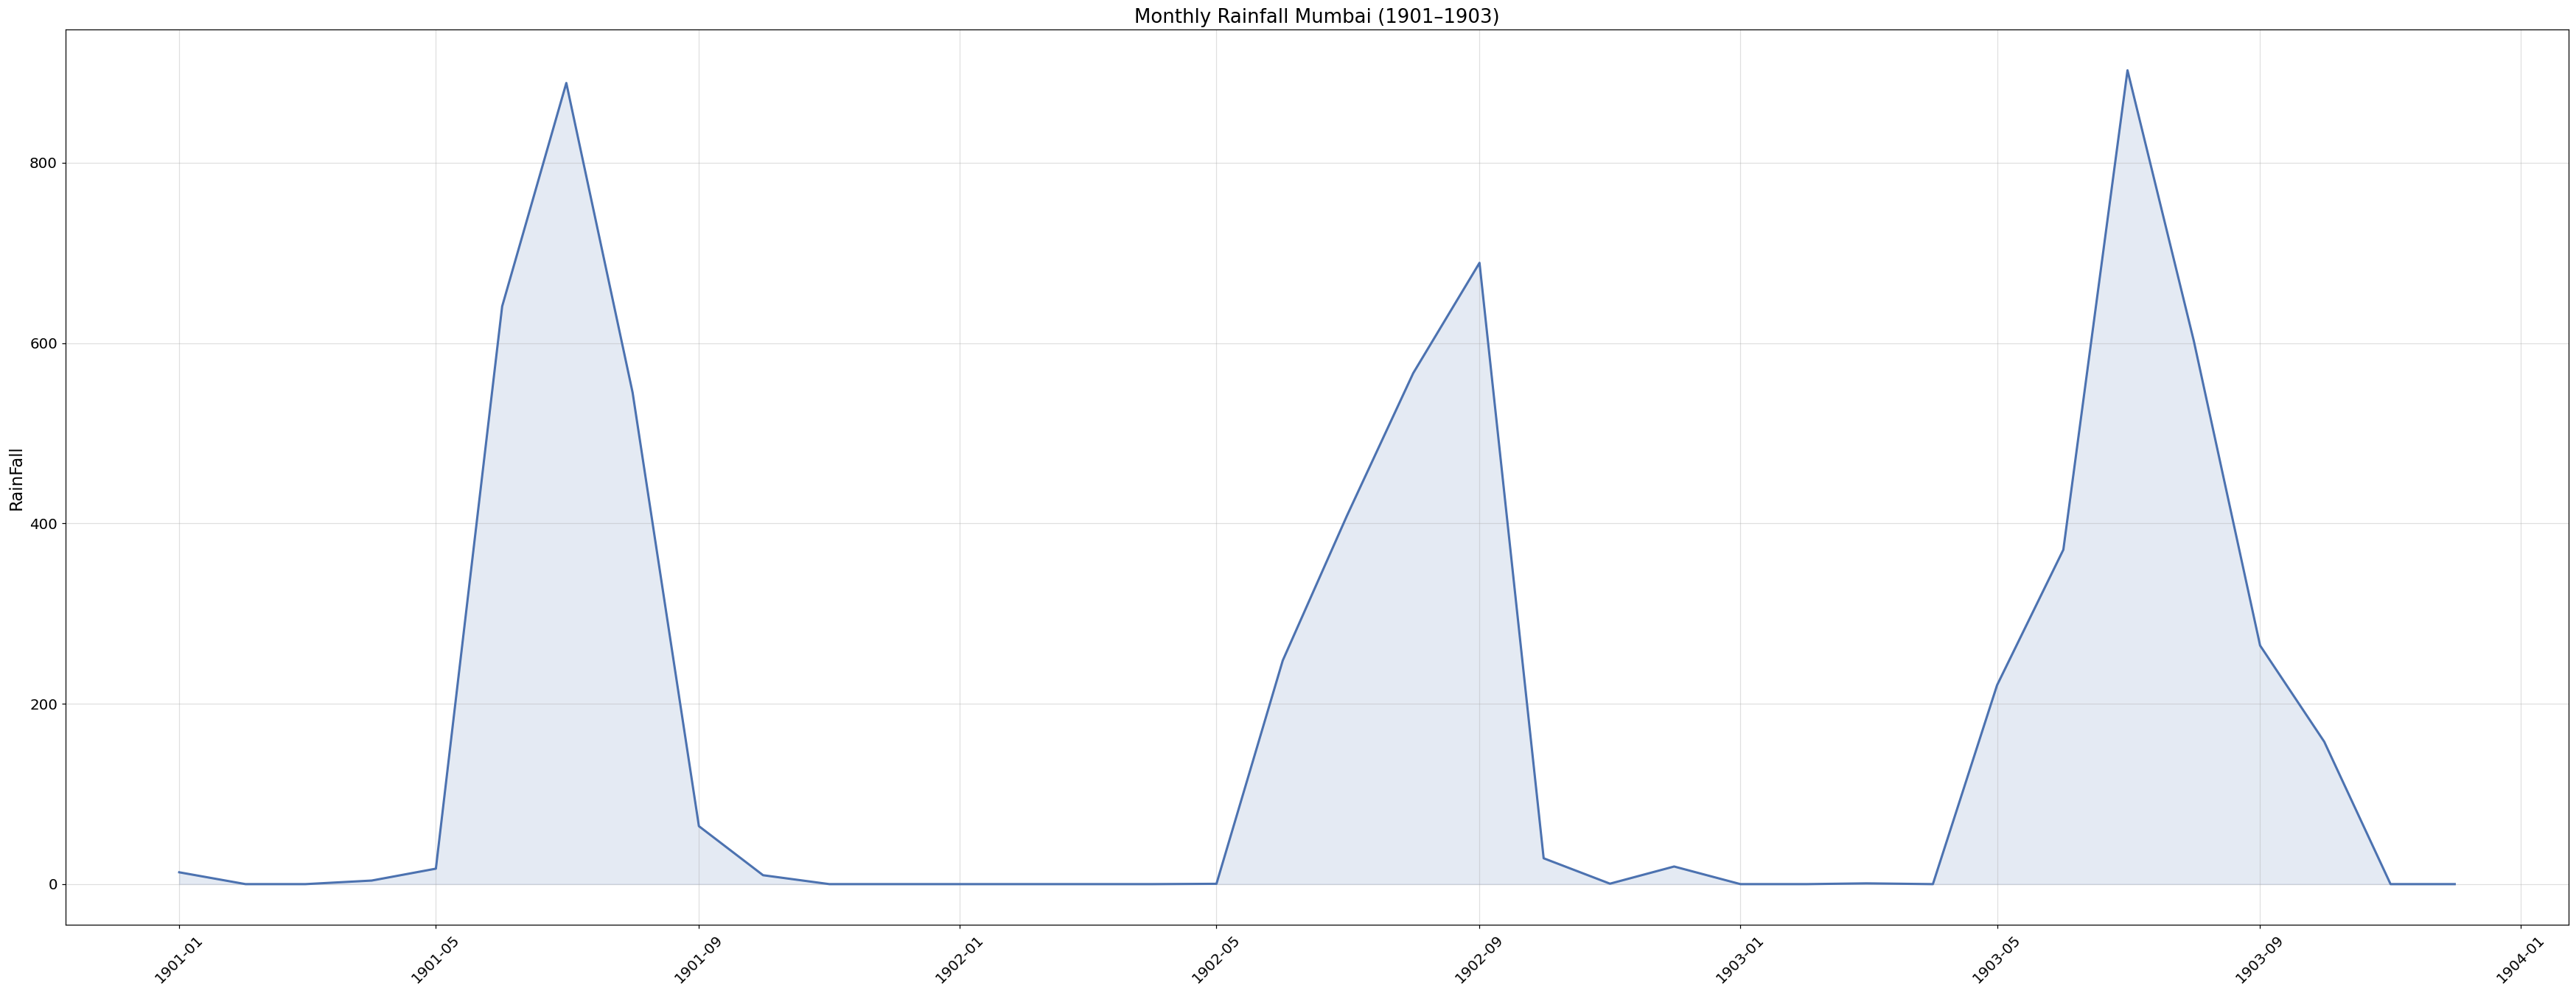

In [400]:
fig, ax = plt.subplots(figsize=(32, 12))
ax.plot(new_df.index, new_df['RainFall'], color=C[0], linewidth=2)
ax.fill_between(new_df.index, new_df['RainFall'], alpha=0.15, color=C[0])
ax.set_title('Monthly Rainfall Mumbai (1901–1903)')
ax.set_ylabel('RainFall')
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

#Plotting Rolling mean and Standard deviation

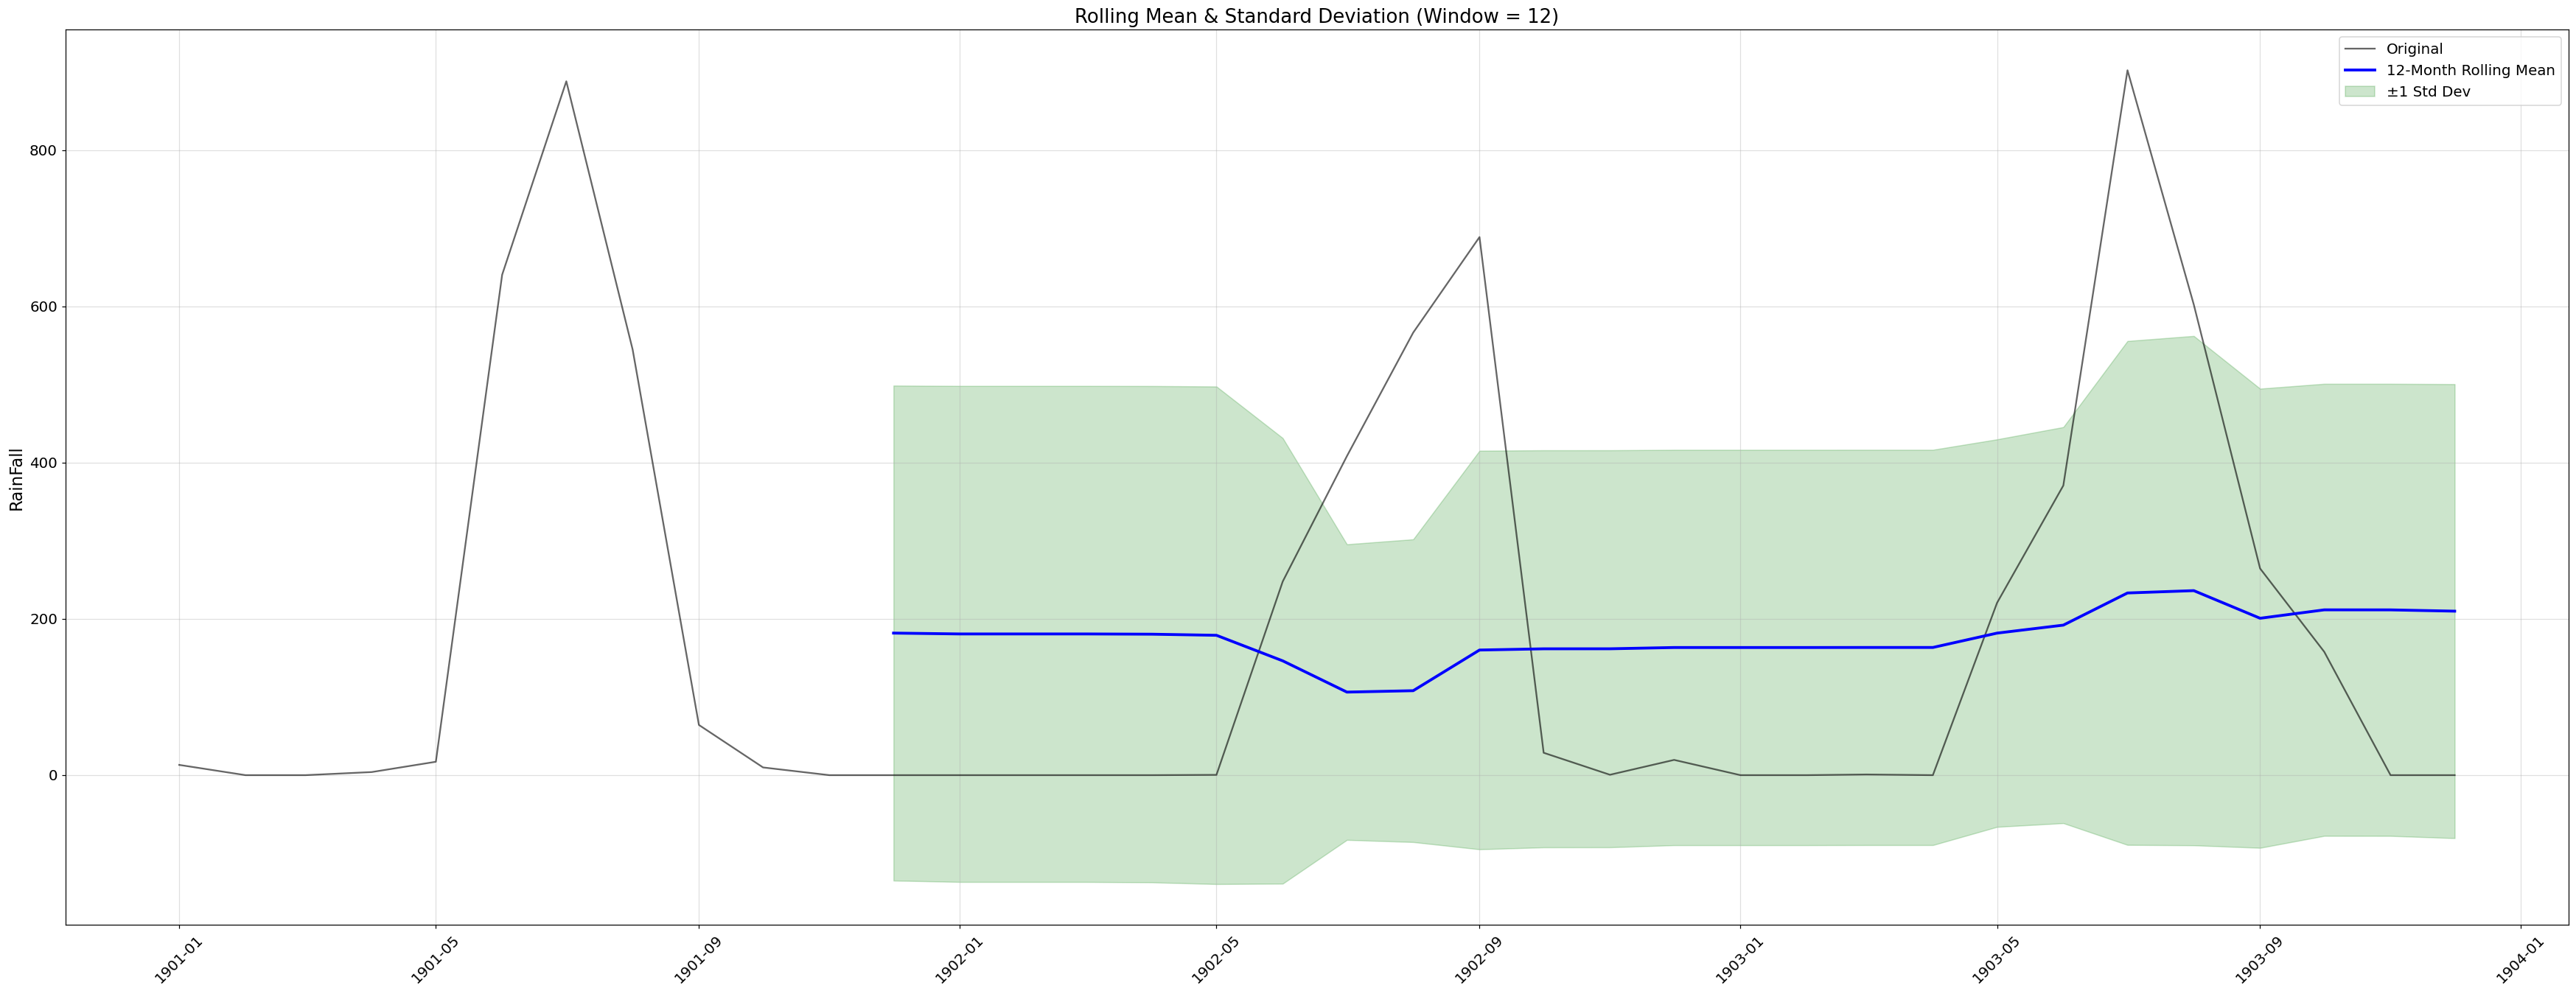

In [404]:
roll = new_df['RainFall'].rolling(12)
fig, ax = plt.subplots(figsize=(32, 12))
ax.plot(new_df.index, new_df['RainFall'],color='black',linewidth=1.5,alpha=0.6,label='Original')
ax.plot(new_df.index, roll.mean(), color='blue', linewidth=2.5,label='12-Month Rolling Mean')
ax.fill_between(new_df.index,roll.mean()-roll.std(),roll.mean()+roll.std(),
                alpha=0.2, color='green',label='±1 Std Dev')
ax.set_title('Rolling Mean & Standard Deviation (Window = 12)')
ax.set_ylabel('RainFall')
ax.legend()
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

# Plotting Box Plot for each Month For Cumalitive All the Years — (Observing Seasonal Pattern in the Data).

<Axes: xlabel='Month_name', ylabel='RainFall'>

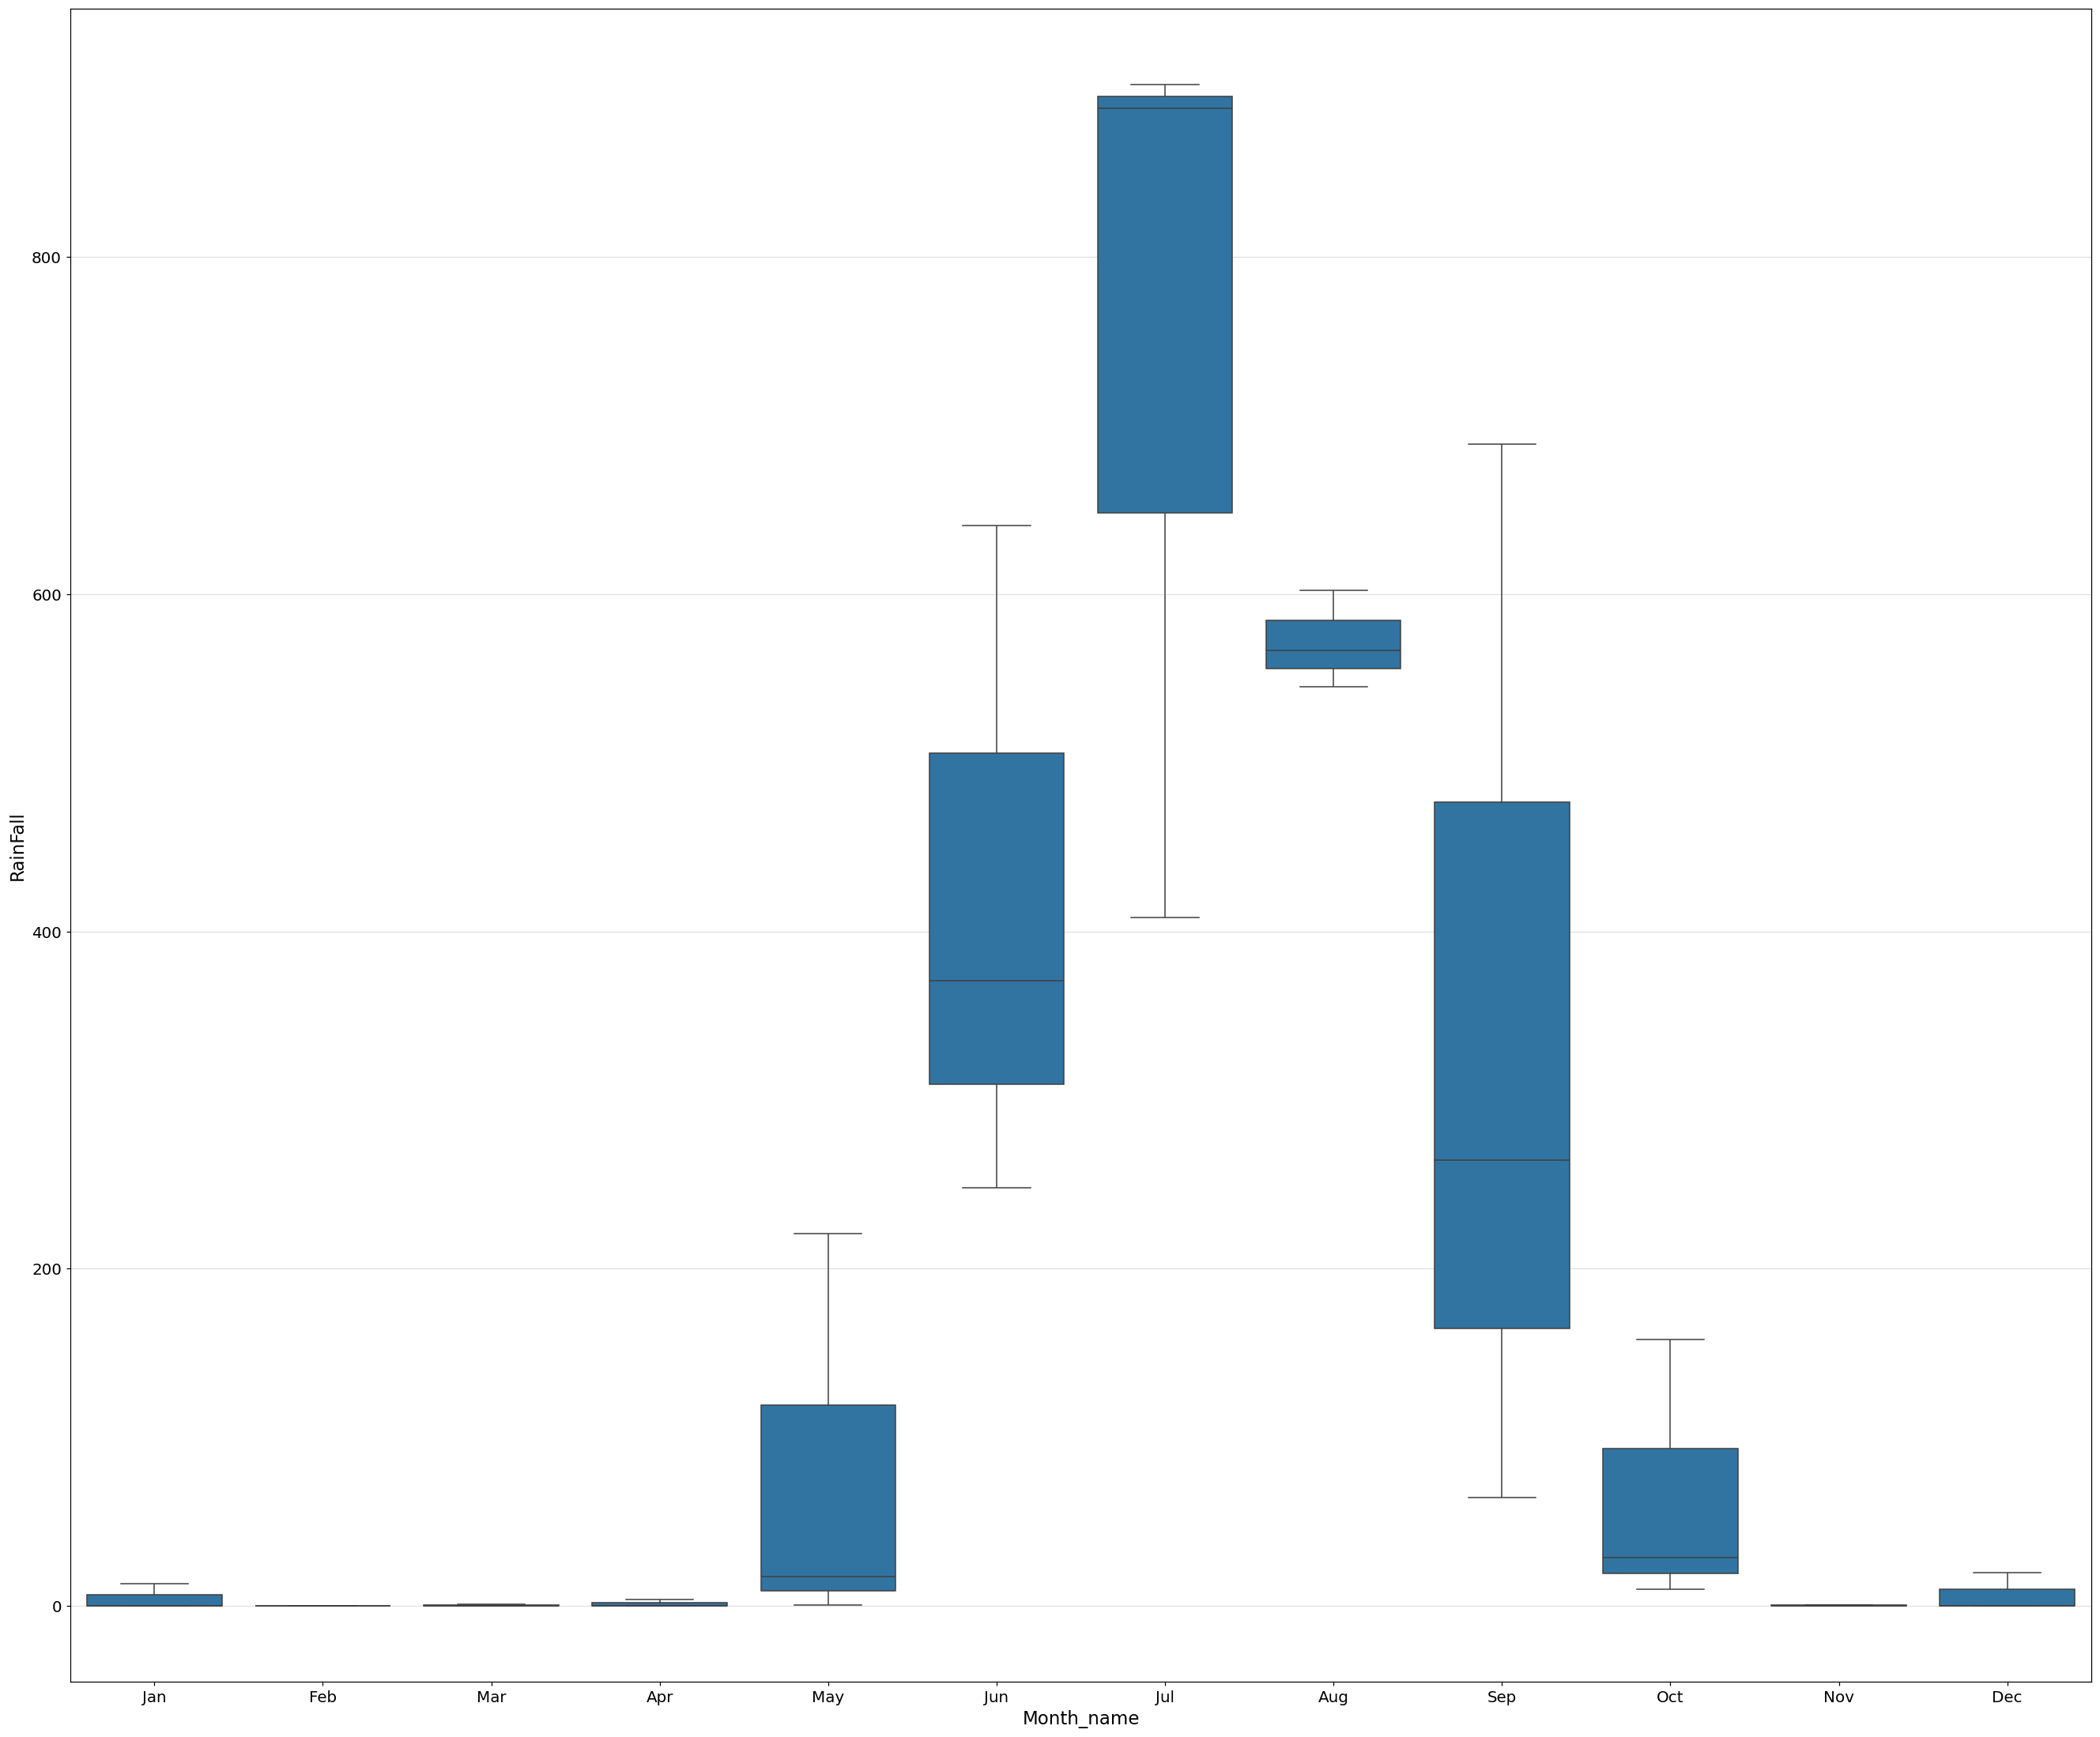

In [330]:
new_df.index = pd.to_datetime(new_df.index)
new_df['Month_name'] = new_df.index.strftime('%b')
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
new_df['Month_name'] = pd.Categorical(new_df['Month_name'], categories=month_order, ordered=True)
#print(new_df.head(10))

fig, ax = plt.subplots(figsize=(30, 25))

'''plt.boxplot(new_df['RainFall'])
plt.title("RainFall by Month — Seasonal Pattern")
plt.show()'''

#fig, ax = plt.subplots()
#sns.boxplot(x="Month_name", y="RainFall", data=new_df, ax=ax)

new_df2['RainFall'] = pd.to_numeric(new_df['RainFall'], errors='coerce')
new_df2 = new_df.dropna(subset=['RainFall'])
new_df2['Month_name'] = new_df['Month_name'].astype(str)
#print("Printing New DF")
#print(new_df2['Month_name'])
sns.boxplot(x='Month_name',y='RainFall',data=new_df2,ax=ax)
#new_df.boxplot(column='RainFall', by='Month_name', ax=ax)
#plt.boxplot(column='RainFall', by='Month_name', ax=ax)
#ax.set_title('RainFall by Month — Seasonal Pattern')
#ax.set_xlabel('Month')
#ax.set_ylabel('RainFall')
#plt.suptitle('')
#plt.tight_layout()
#plt.show()

#new_df.drop(columns=['Month_name'], inplace=True)

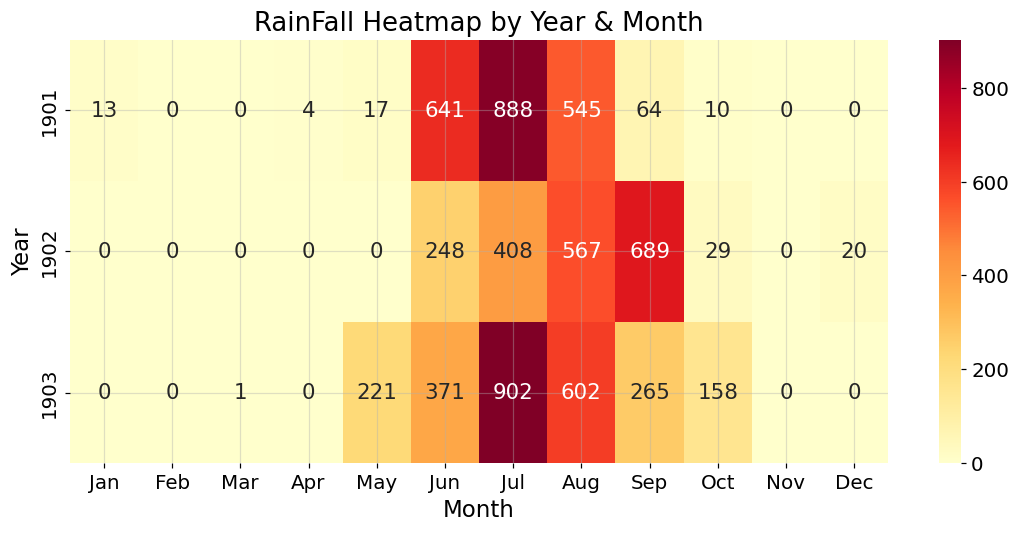

In [92]:
temp = new_df.copy()

# Extract year and month
temp['Year'] = temp.index.year
temp['Month_Num'] = temp.index.month

# Create Year × Month table
pivot = temp.pivot_table(
    values='RainFall',
    index='Year',
    columns='Month_Num'
)

# Month names
pivot.columns = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

# Heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    pivot,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd'
)

plt.title('RainFall Heatmap by Year & Month')
plt.xlabel('Month')
plt.ylabel('Year')

plt.show()

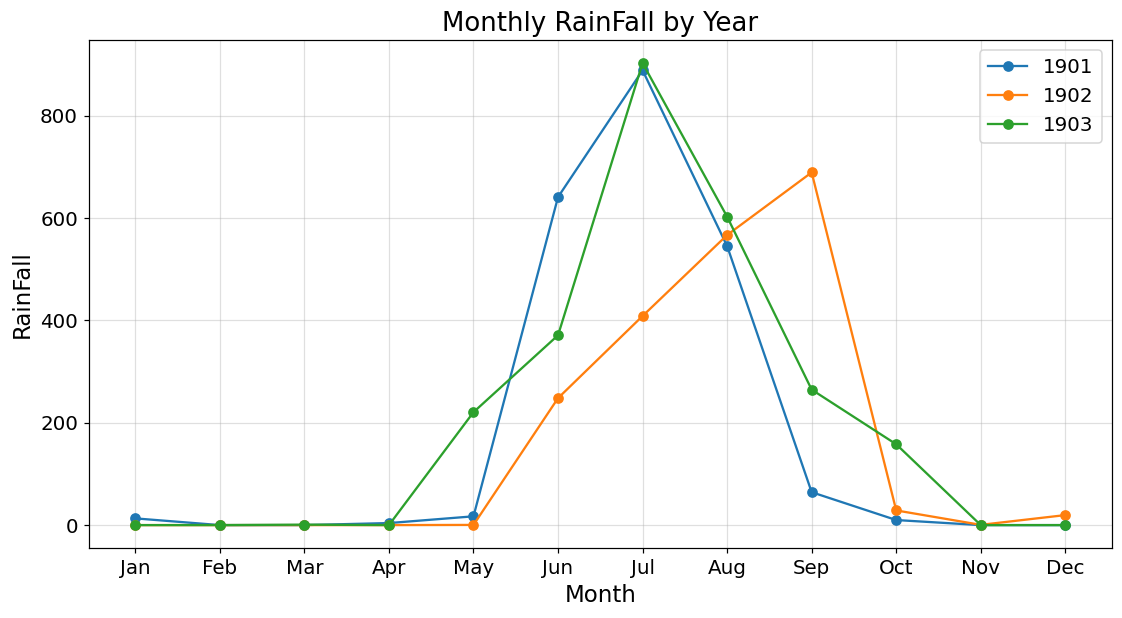

In [95]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(12, 6))
years = new_df.index.year.unique()

for year in years:
    vals = new_df[new_df.index.year == year]['RainFall'].values

    ax.plot(
        months,
        vals,
        marker='o',
        label=str(year)
    )

ax.set_title('Monthly RainFall by Year')
ax.set_xlabel('Month')
ax.set_ylabel('RainFall')
ax.legend()
plt.show()

#Additive Decomposition.

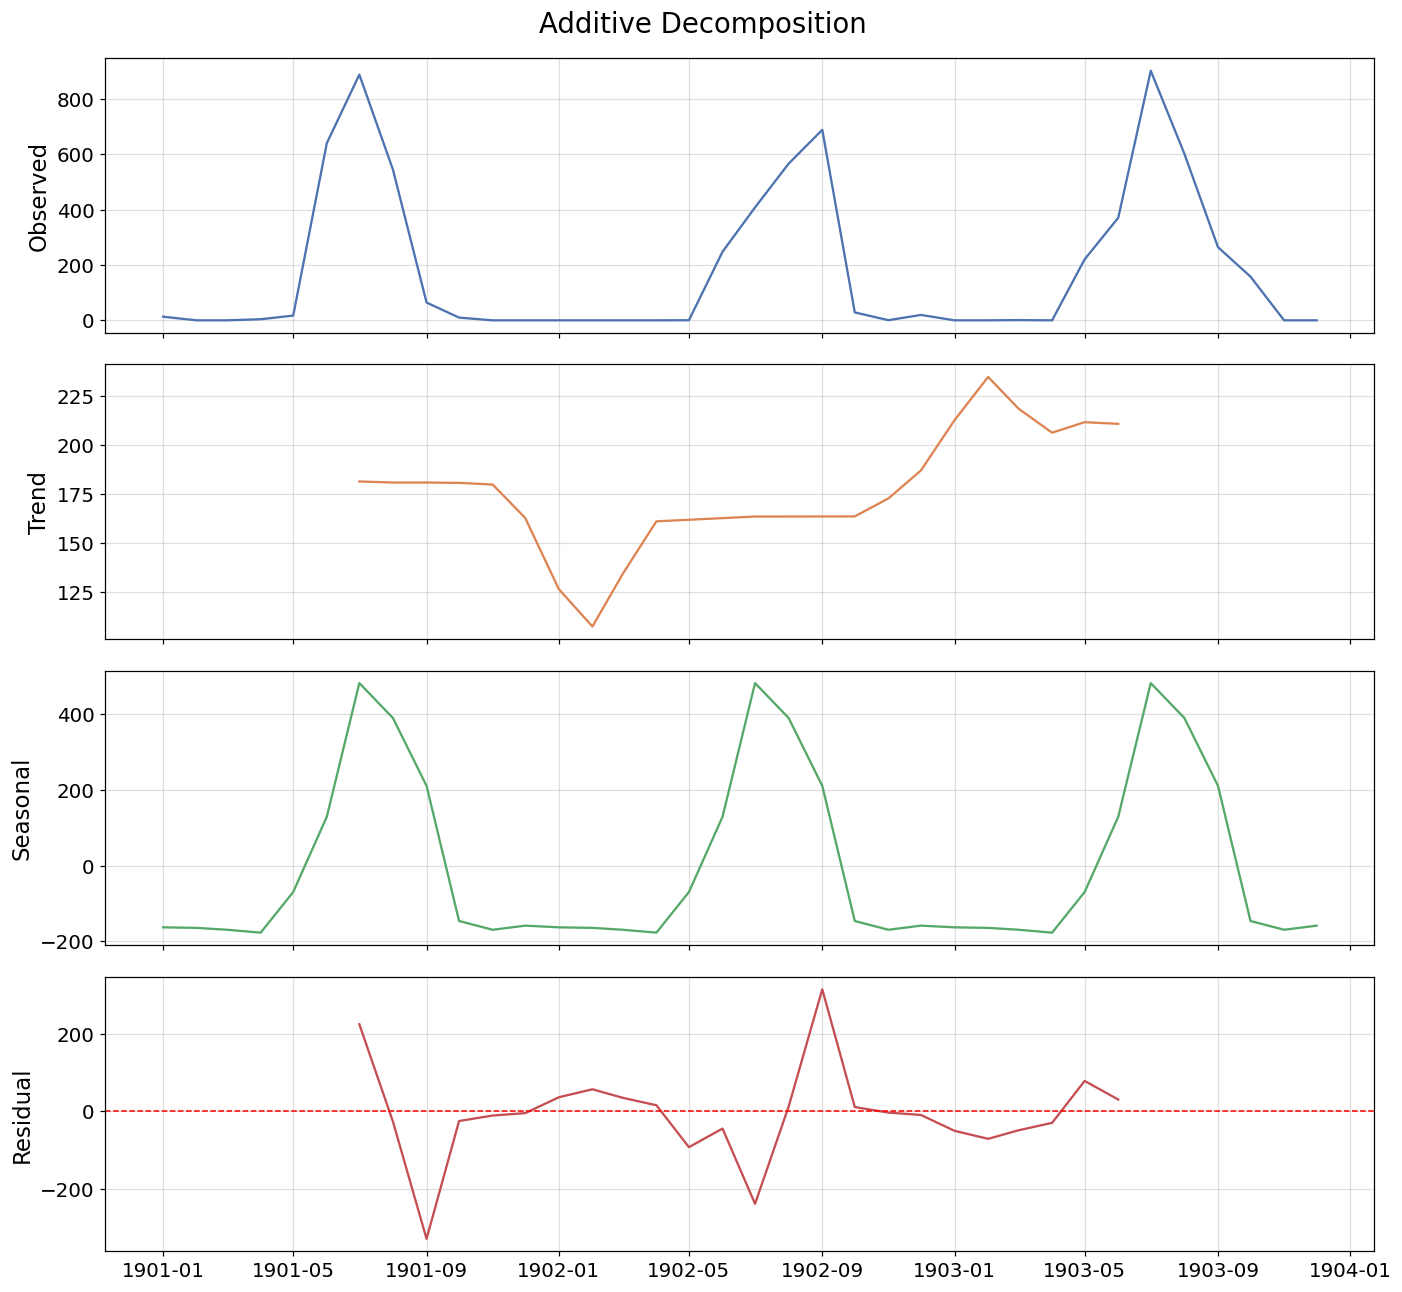

In [100]:
result = seasonal_decompose(new_df['RainFall'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
fig.suptitle('Additive Decomposition', fontsize=18)
axes[0].plot(new_df.index, result.observed,  color=C[0]); axes[0].set_ylabel('Observed')
axes[1].plot(new_df.index, result.trend,     color=C[1]); axes[1].set_ylabel('Trend')
axes[2].plot(new_df.index, result.seasonal,  color=C[2]); axes[2].set_ylabel('Seasonal')
axes[3].plot(new_df.index, result.resid,     color=C[3]); axes[3].set_ylabel('Residual')
axes[3].axhline(1, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

# STL Decomposition (more Robust).

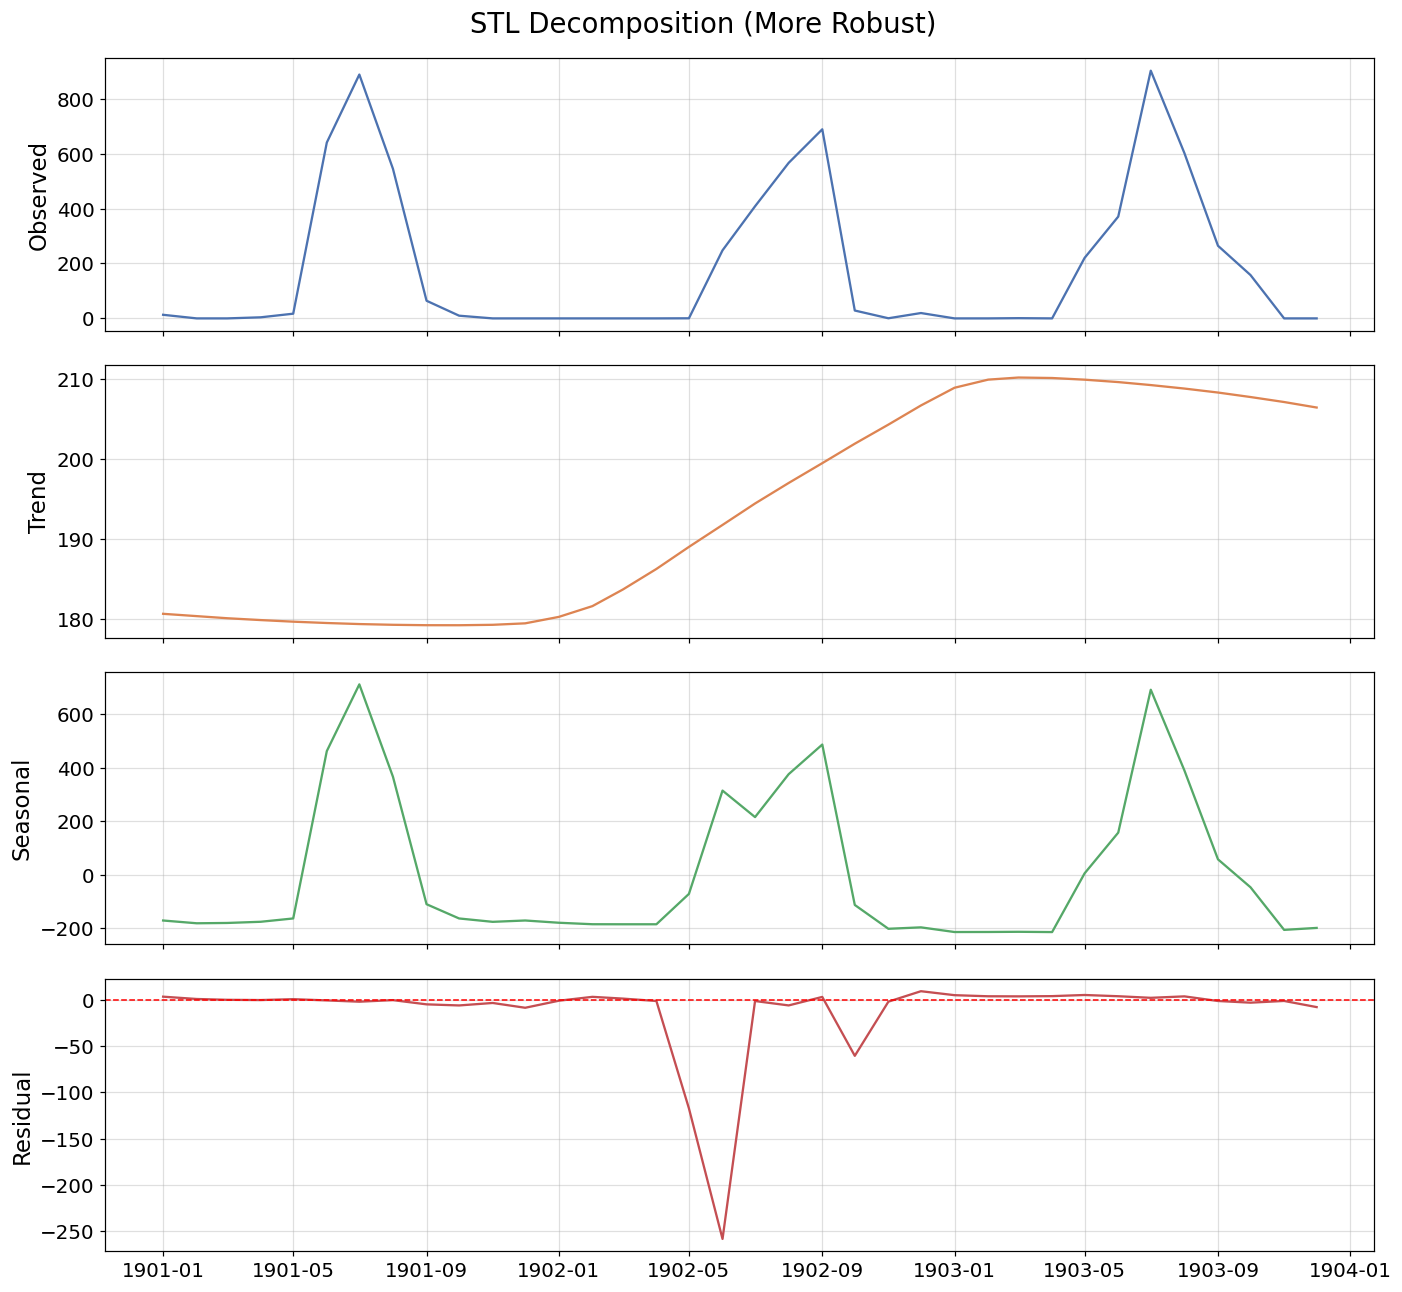

Seasonal Strength: 0.971  (above 0.64 = strong)


In [104]:
stl = STL(new_df['RainFall'], period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
fig.suptitle('STL Decomposition (More Robust)', fontsize=18)

axes[0].plot(new_df.index, new_df['RainFall'], color=C[0]); axes[0].set_ylabel('Observed')
axes[1].plot(new_df.index, stl.trend,        color=C[1]); axes[1].set_ylabel('Trend')
axes[2].plot(new_df.index, stl.seasonal,     color=C[2]); axes[2].set_ylabel('Seasonal')
axes[3].plot(new_df.index, stl.resid,        color=C[3]); axes[3].set_ylabel('Residual')
axes[3].axhline(0, color='red', linestyle='--', linewidth=1)

plt.tight_layout()
plt.show()

strength = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print(f'Seasonal Strength: {strength:.3f}  (above 0.64 = strong)')

# Seasonal indices Bar chart.

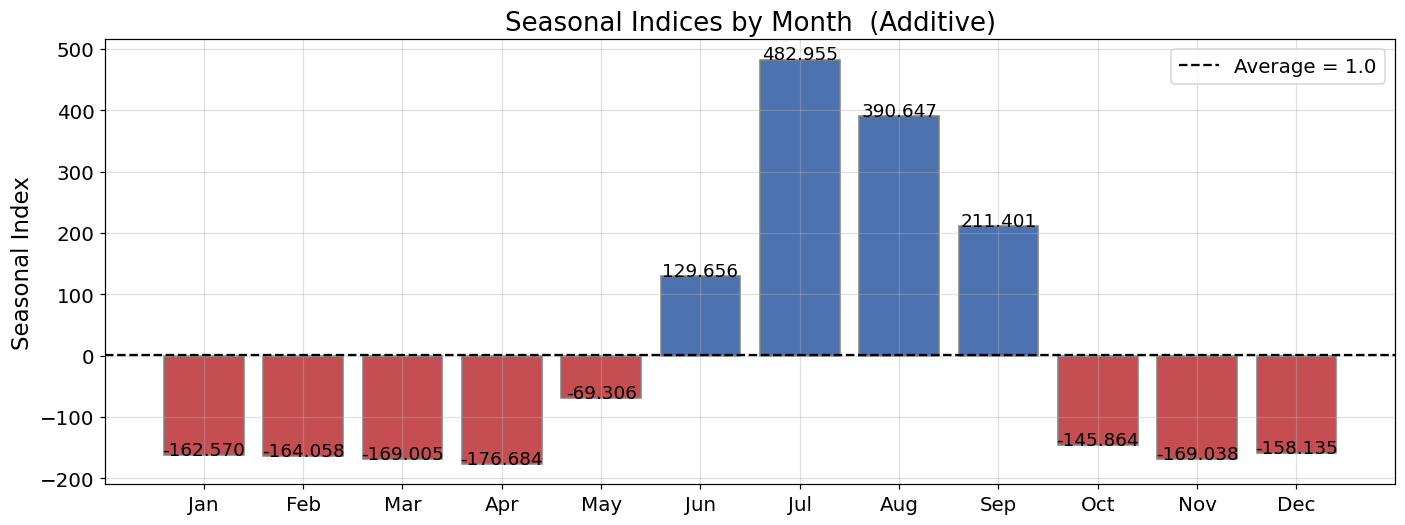

In [105]:
si = result.seasonal[:12].copy()
si.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(13, 5))
colors = [C[3] if v < 1 else C[0] for v in si.values]
ax.bar(si.index, si.values, color=colors, edgecolor='grey')
ax.axhline(1.0, color='black', linestyle='--', linewidth=1.5, label='Average = 1.0')

for i, (month, val) in enumerate(si.items()):
    ax.text(i, val + 0.008, f'{val:.3f}', ha='center', fontsize=12)

ax.set_title('Seasonal Indices by Month (Additive)')
ax.set_ylabel('Seasonal Index')
ax.legend()
plt.tight_layout()
plt.show()

#Stationarity Tests
#Augmented Dicky Fuller Test.
- **ADF:** H₀ = non-stationary. Reject if p < 0.05 → stationary  
- **KPSS:** H₀ = stationary. Reject if p < 0.05 → non-stationary

In [331]:
def check_stationarity(series, name):
    adf_p  = adfuller(series.dropna(), autolag='AIC')[1]
    kpss_p = kpss(series.dropna(), regression='c', nlags='auto')[1]
    adf_result  = 'STATIONARY'     if adf_p  < 0.05 else 'NON-STATIONARY'
    kpss_result = 'NON-STATIONARY' if kpss_p < 0.05 else 'STATIONARY'
    print(f'--- {name} ---')
    print(f'  ADF  p={adf_p:.4f}  → {adf_result}')
    print(f'  KPSS p={kpss_p:.4f}  → {kpss_result}')
    print()

check_stationarity(new_df['RainFall'], 'Original Series')

--- Original Series ---
  ADF  p=0.0010  → STATIONARY
  KPSS p=0.1000  → STATIONARY



#Make the Series Stationary
#Steps:

#Log transform → stabilizes variance Seasonal diff (lag=12) → removes seasonality. First diff (lag=1) → removes trend

In [162]:
new_df1['RainFall'] = new_df1['RainFall'].astype(float)

new_df1['log']= np.log(new_df1['RainFall'])
new_df1['log_d12']  = new_df1['log'].diff(12)
new_df1['log_d12_d1'] = new_df1['log_d12'].diff(1)
#new_df1['Log_Salary'] = np.log(new_df1['RainFall'])
#print(new_df1.head())

#new_df1['log']= new_df1['log'].replace([np.inf, -np.inf], np.nan).dropna()
#print(new_df1['log'])
new_df1.replace([np.inf, -np.inf], 0, inplace=True)
# Check stationarity at each step
check_stationarity(new_df1['log'],'Log')
check_stationarity(new_df1['log_d12'],'Log + Seasonal Diff(12)')
check_stationarity(new_df1['log_d12_d1'],'Log + Diff(12) + Diff(1)')

--- Log ---
  ADF  p=0.0004  → STATIONARY
  KPSS p=0.1000  → STATIONARY

--- Log + Seasonal Diff(12) ---
  ADF  p=0.0048  → STATIONARY
  KPSS p=0.1000  → STATIONARY

--- Log + Diff(12) + Diff(1) ---
  ADF  p=0.0098  → STATIONARY
  KPSS p=0.1000  → STATIONARY



#Plotting: Original Time Series

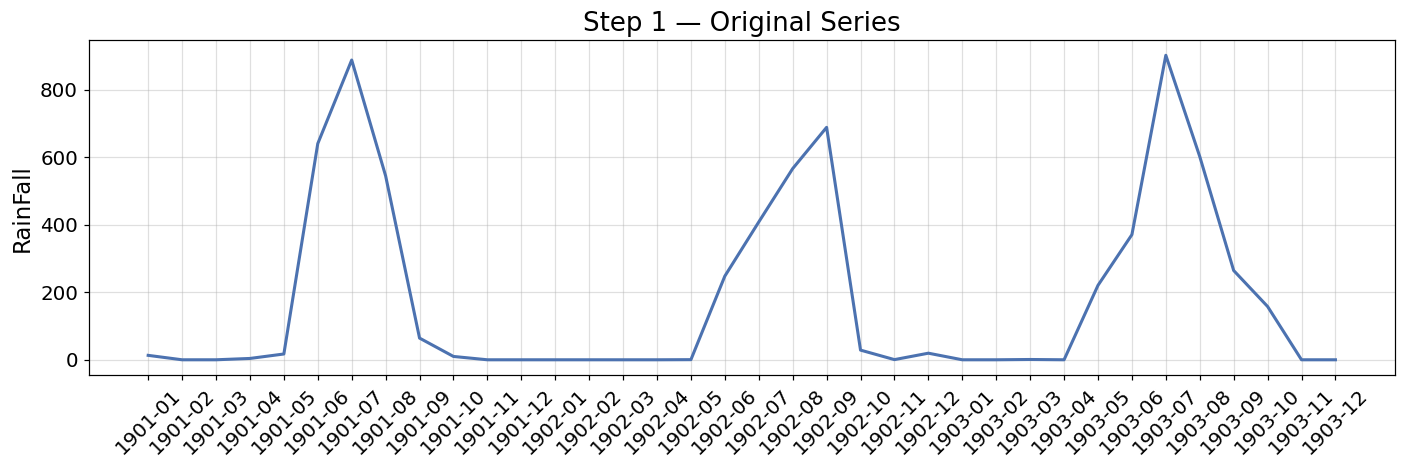

In [167]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(new_df1.index, new_df1['RainFall'], color=C[0], linewidth=2)
ax.set_title('Step 1 — Original Time Series')
ax.set_ylabel('RainFall')
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

# Plotting: Log Transformation of Data i.e RainFall column.

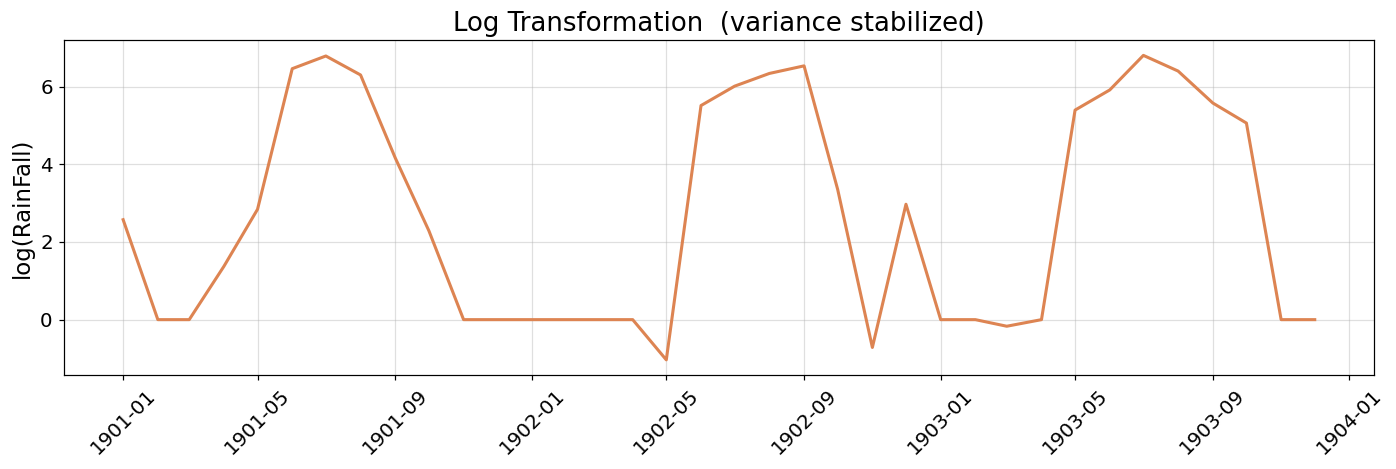

In [386]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(new_df1.index, new_df1['log'], color=C[1], linewidth=2)
ax.set_title('Log Transformation  (variance stabilized)')
ax.set_ylabel('log(RainFall)')
plt.tight_layout()
plt.xticks(rotation=45)
plt.show()

# Plotting: Log Transformation + Seasonal Difference.

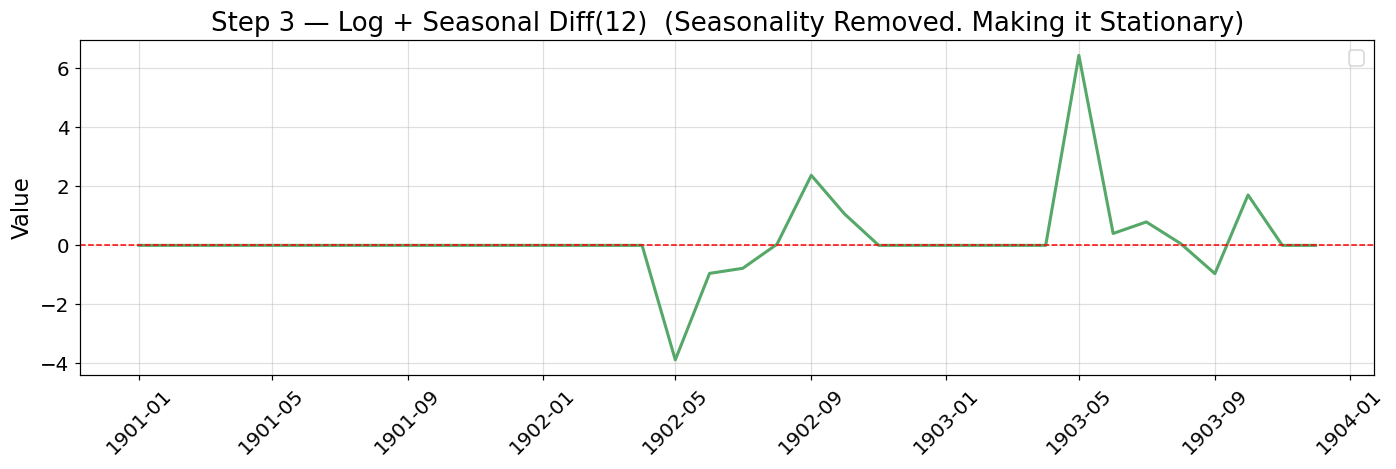

In [397]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(new_df1.index, new_df1['log_d12'], color=C[2], linewidth=2)
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_title('Step 3 — Log + Seasonal Diff(12)  (Seasonality Removed. Making it Stationary)')
ax.set_ylabel('Value')
plt.tight_layout()
ax.legend()
plt.xticks(rotation=45)
plt.show()

# Now the Time Series is Stationary. Plotting the Stationary Time Series.

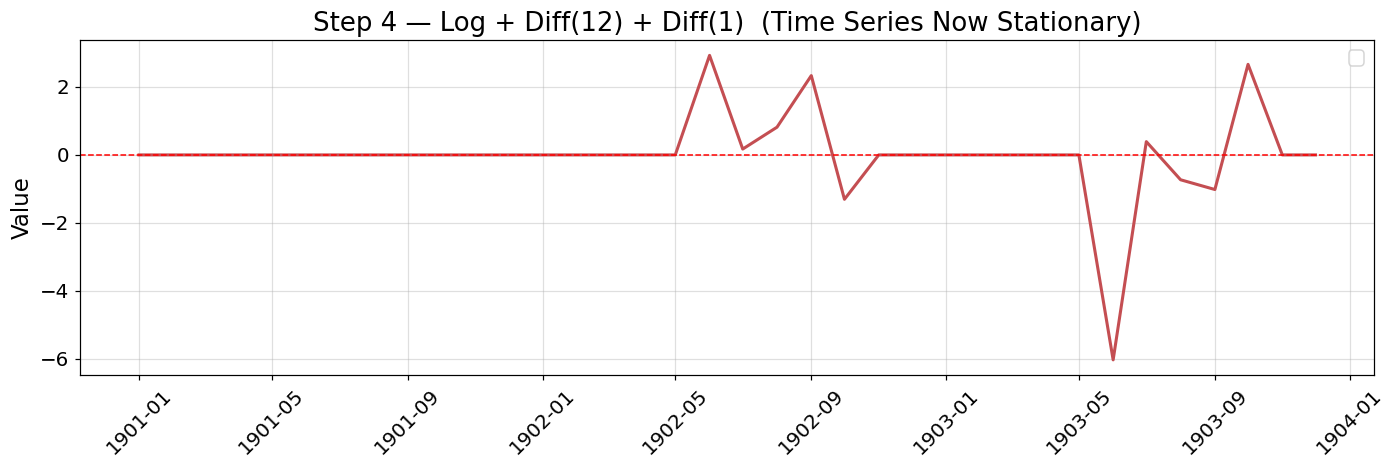

In [398]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(new_df1.index, new_df1['log_d12_d1'], color=C[3], linewidth=2)
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_title('Step 4 — Log + Diff(12) + Diff(1)  (Time Series Now Stationary)')
ax.set_ylabel('Value')
plt.tight_layout()
ax.legend()
plt.xticks(rotation=45)
plt.show()

#Plotting Auto Correlation Function Plots(ACF) & Partial Auto Correlation Function Plots(PACF).

#- ACF cuts off at lag q → MA(q)
#- PACF cuts off at lag p → AR(p)

#Auto Correlation Function Plot.

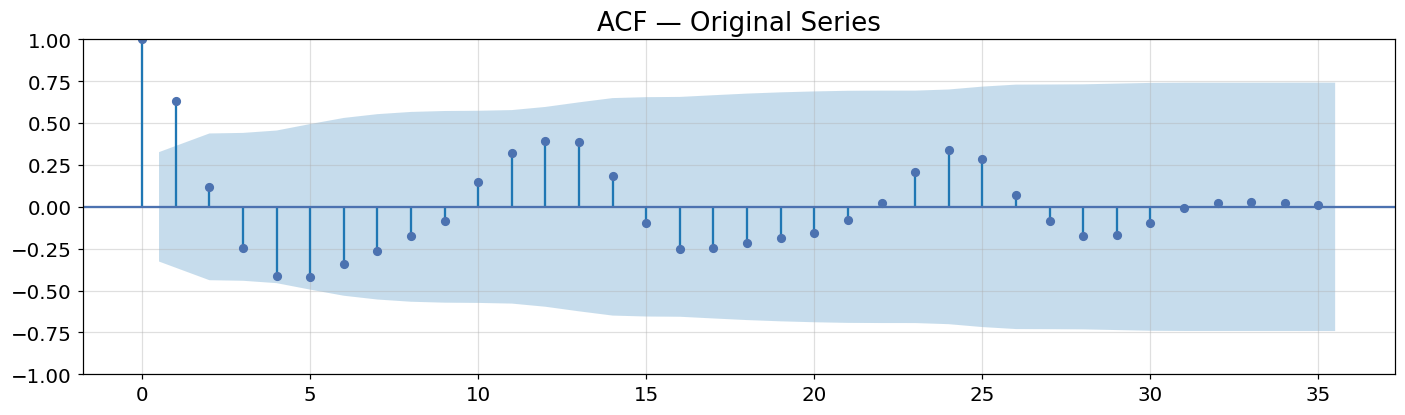

In [399]:
# ACF — Original Series
fig, ax = plt.subplots(figsize=(13, 4))
plot_acf(new_df1['RainFall'], lags=35, ax=ax, color=C[0])
ax.set_title('ACF — Original Series')
plt.tight_layout()
plt.show()

#Partial Auto Correlation Function Plot.

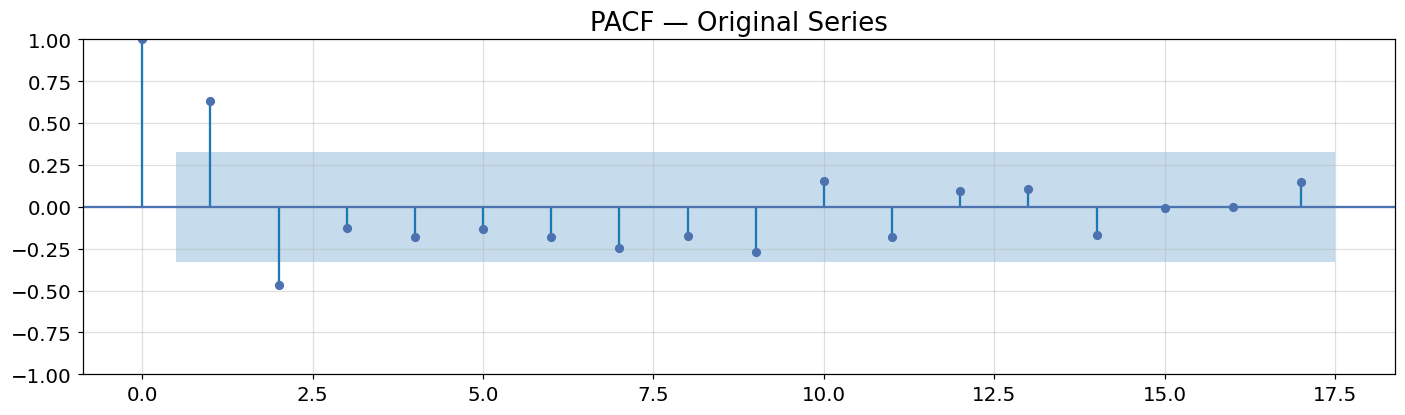

In [182]:
fig, ax = plt.subplots(figsize=(13, 4))
plot_pacf(new_df1['RainFall'], lags=17, ax=ax, method='ywm', color=C[0])
ax.set_title('PACF — Original Series')
plt.tight_layout()
plt.show()

# Auto Correlation Function Plot after making the Series Stationary.

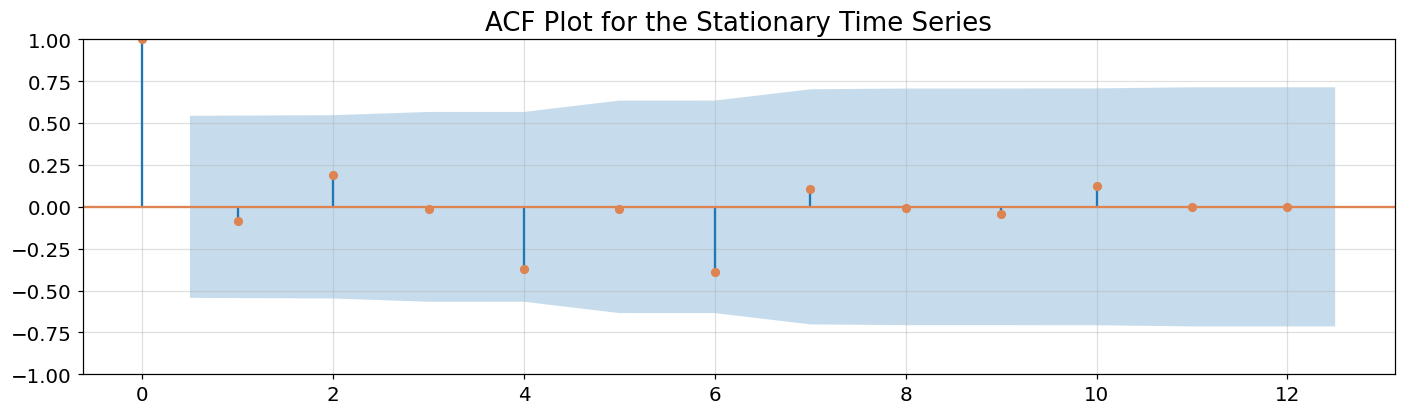

In [185]:
stationary = new_df1['log_d12_d1'].dropna()

fig, ax = plt.subplots(figsize=(13, 4))
plot_acf(stationary, lags=12, ax=ax, color=C[1])
ax.set_title('ACF Plot for the Stationary Time Series')
plt.tight_layout()
plt.show()

#Partial Auto Correlation Function Plot after making the Series Stationary.

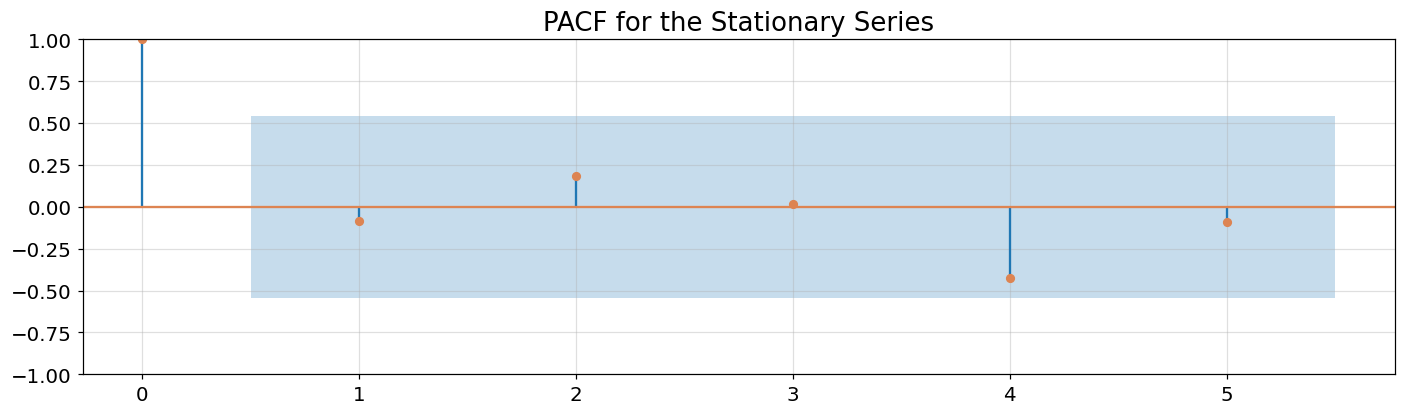

In [188]:
fig, ax = plt.subplots(figsize=(13, 4))
plot_pacf(stationary, lags=5, ax=ax, method='ywm', color=C[1])
ax.set_title('PACF for the Stationary Series')
plt.tight_layout()
plt.show()

#Train-Test Split of the Data & Smoothing of the Data.

#Train Test Split.

In [200]:
train = new_df1['RainFall'][:'1902-12']
test  = new_df1['RainFall']['1903-01':]

train.index = pd.to_datetime(train.index)
test.index = pd.to_datetime(test.index)

train_dt_object = train.index[0].to_pydatetime()
test_dt_object = test.index[0].to_pydatetime()
train_dt_object = datetime.strptime(str(train.index[0]),'%Y-%m-%d %H:%M:%S')
test_dt_object = datetime.strptime(str(test.index[0]),'%Y-%m-%d %H:%M:%S')
print(f'Train: {len(train)} months  ({train_dt_object.date()} to {train.index[-1].date()})')
print(f'Test : {len(test)} months  ({test_dt_object.date()} to {test.index[-1].date()})')

results = {}   # will store all model scores

def score(name, actual, predicted):
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    results[name] = {'MAE': round(mae,2), 'RMSE': round(rmse,2), 'MAPE': round(mape,2)}
    print(f'{name:<30}  MAE={mae:.1f}  RMSE={rmse:.1f}  MAPE={mape:.2f}%')

Train: 24 months  (1901-01-01 to 1902-12-01)
Test : 12 months  (1903-01-01 to 1903-12-01)


# Fit smoothing models.

In [207]:
ses  = SimpleExpSmoothing(train).fit(optimized=True)
holt = ExponentialSmoothing(train, trend='add').fit(optimized=True)
hw_a = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12).fit(optimized=True)
#hw_m = ExponentialSmoothing(train, trend='mul', seasonal='mul', seasonal_periods=12).fit(optimized=True)

ses_pred  = pd.Series(ses.forecast(len(test)),  index=test.index)
holt_pred = pd.Series(holt.forecast(len(test)), index=test.index)
hw_a_pred = pd.Series(hw_a.forecast(len(test)), index=test.index)
#hw_m_pred = pd.Series(hw_m.forecast(len(test)), index=test.index)

score('Simple Exp Smoothing',       test, ses_pred)
score('Holt Linear',                test, holt_pred)
score('Holt-Winters Additive',      test, hw_a_pred)
#score('Holt-Winters Additive',test, hw_m_pred)

Simple Exp Smoothing            MAE=209.8  RMSE=337.2  MAPE=inf%
Holt Linear                     MAE=209.5  RMSE=336.1  MAPE=inf%
Holt-Winters Additive           MAE=86.7  RMSE=123.5  MAPE=inf%




# Smoothing forecast comparison.


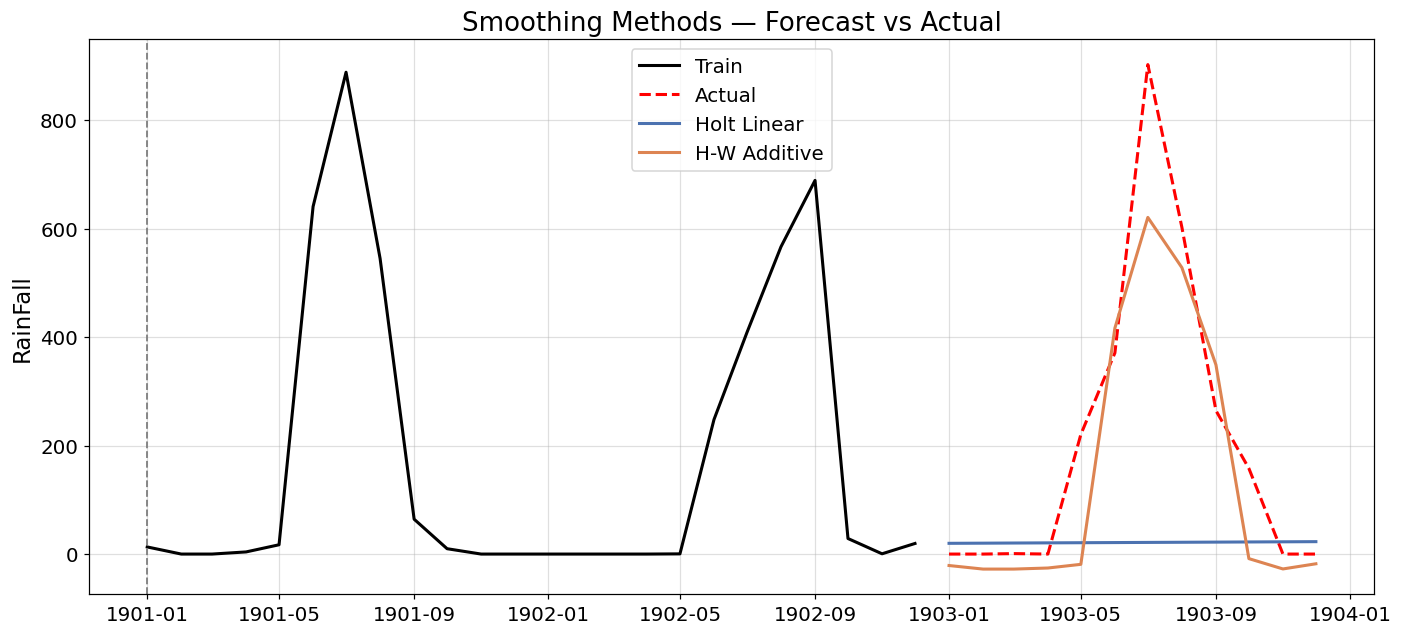

In [384]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(train.index, train,     color='black',  linewidth=2,   label='Train')
ax.plot(test.index,  test,      color='red',  linewidth=2,   label='Actual', linestyle='--')
ax.plot(test.index,  holt_pred, color=C[0],     linewidth=2,   label='Holt Linear')
ax.plot(test.index,  hw_a_pred, color=C[1],     linewidth=2,   label='H-W Additive')
#ax.plot(test.index,  hw_m_pred, color=C[2],     linewidth=2.5, label='H-W Multiplicative')
ax.axvline(pd.Timestamp('1901-01'), color='grey', linestyle='--', linewidth=1.2)
ax.set_title('Smoothing Methods — Forecast vs Actual')
ax.set_ylabel('RainFall')
ax.legend()
plt.tight_layout()
plt.show()

#Applying ARIMA Model.
#ARIMA(p, d, q): p = AR lags, d = differencing, q = MA lags.

In [333]:
log_train = np.log(train)
log_test  = np.log(test)

#print("Log Train",log_train)
log_train.replace([np.inf, -np.inf], 0, inplace=True)
log_test.replace([np.inf, -np.inf], 0, inplace=True)

arima = ARIMA(log_train, order=(2, 1, 0)).fit()
arima_pred = pd.Series(np.exp(arima.forecast(len(test))), index=test.index)
print("ARIMA Predictions \n",arima_pred)
score('ARIMA(2,1,1)', test, arima_pred)

ARIMA Predictions 
 1903-01-01    50.277640
1903-02-01    38.483552
1903-03-01    33.499988
1903-04-01    33.827819
1903-05-01    34.383214
1903-06-01    34.424151
1903-07-01    34.369413
1903-08-01    34.357487
1903-09-01    34.361739
1903-10-01    34.363609
1903-11-01    34.363408
1903-12-01    34.363179
Name: predicted_mean, dtype: float64
ARIMA(2,1,1)                    MAE=211.4  RMSE=329.3  MAPE=inf%


#Using Auto ARIMA to find the Best Order.

In [332]:
print('\nRunning auto_arima...')
best_arima = pm.auto_arima(log_train, seasonal=False, stepwise=True,
                            error_action='ignore', trace=True)
auto_arima_pred = pd.Series(np.exp(best_arima.predict(len(test))), index=test.index)
print(f'\nBest order: {best_arima.order}')
score(f'auto_ARIMA{best_arima.order}', test, auto_arima_pred)


Running auto_arima...
Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=112.333, Time=0.31 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=133.578, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=110.453, Time=0.05 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=119.620, Time=0.14 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=111.631, Time=0.07 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=111.699, Time=0.10 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=113.608, Time=0.10 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=109.206, Time=0.07 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=120.314, Time=0.02 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=108.292, Time=0.07 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=108.921, Time=0.17 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.70 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=109.433, Time=0.21 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.87 sec

Best model:  ARIMA(2,0,0)(0,0,0

#Using parameters provided by AUTO Arima for the Best Order to make Predictions.

In [336]:
arima = ARIMA(log_train, order=(2,0,0)).fit()
arima_pred = pd.Series(np.exp(arima.forecast(len(test))), index=test.index)
print("ARIMA Predictions \n",arima_pred)
score('ARIMA(2,0,0)', test, arima_pred)

ARIMA Predictions 
 1903-01-01    66.942226
1903-02-01    52.561074
1903-03-01    27.243857
1903-04-01    16.649998
1903-05-01    13.665589
1903-06-01    13.709284
1903-07-01    14.761898
1903-08-01    15.738971
1903-09-01    16.216217
1903-10-01    16.269096
1903-11-01    16.141232
1903-12-01    16.010513
Name: predicted_mean, dtype: float64
ARIMA(2,0,0)                    MAE=218.6  RMSE=340.7  MAPE=inf%


# ARIMA Forecast Plot.

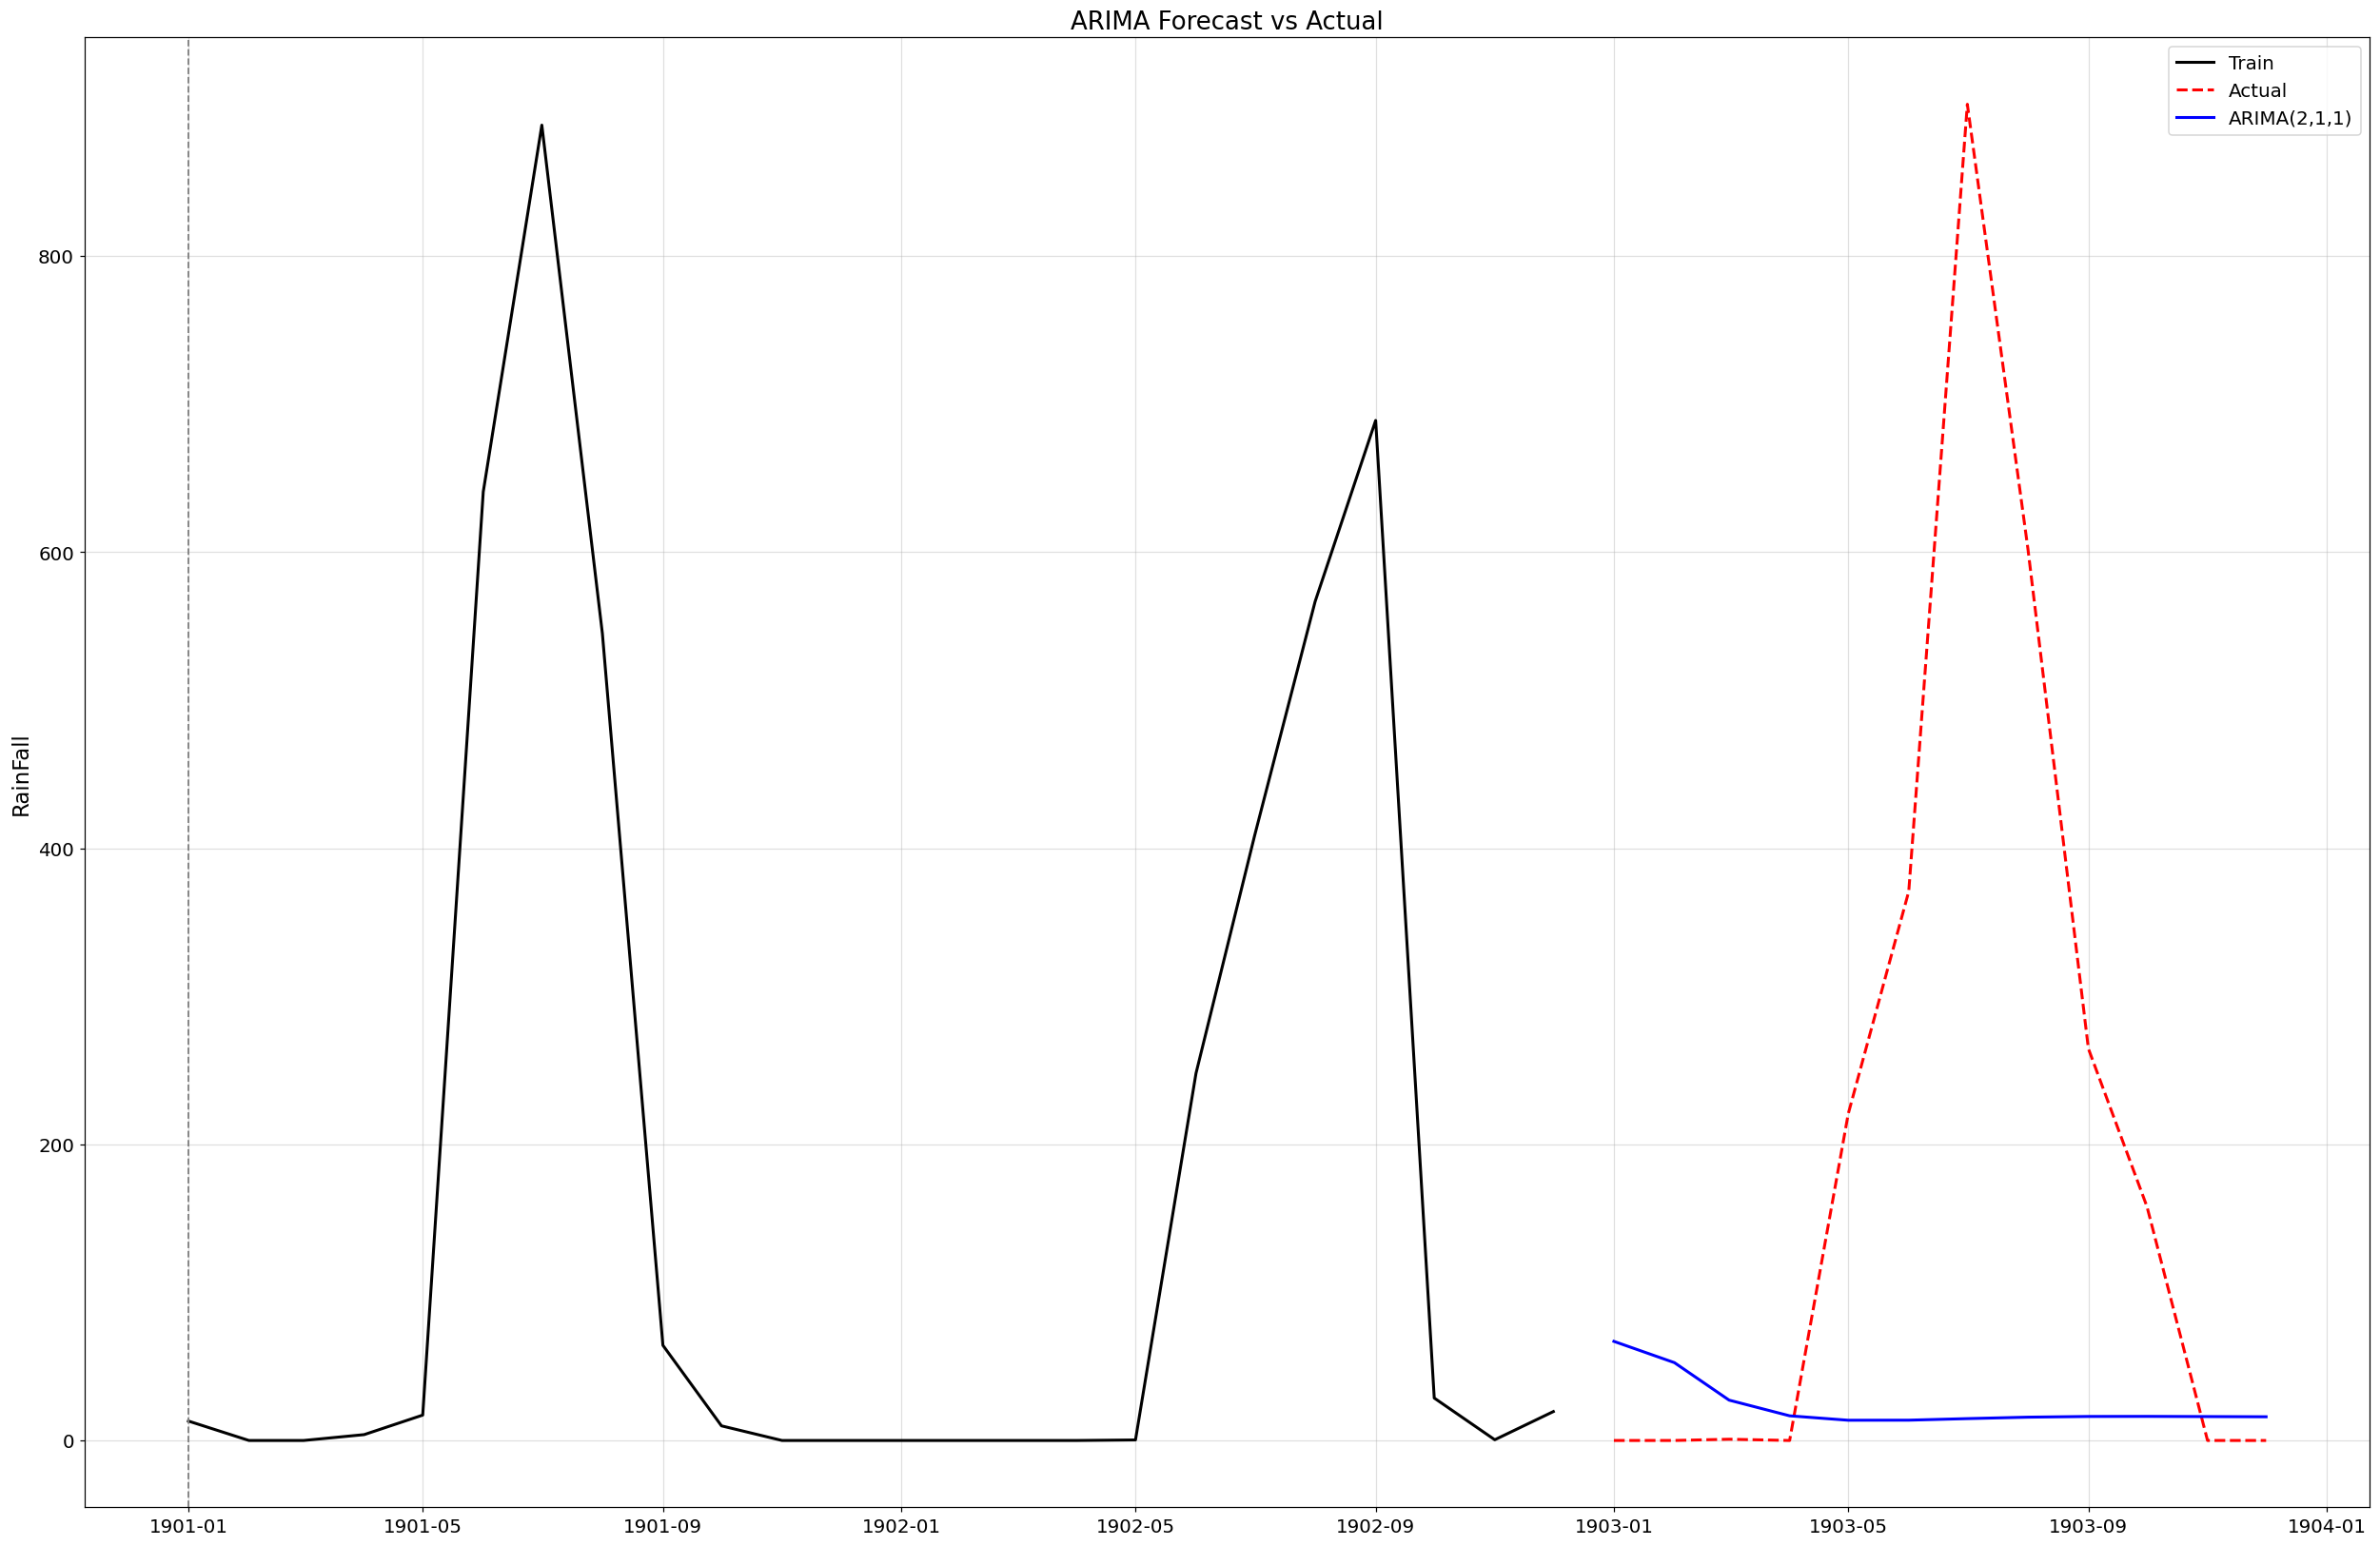

In [382]:
fig, ax = plt.subplots(figsize=(23, 15))
ax.plot(train.index,train,color='black',linewidth=2,label='Train')
ax.plot(test.index,test,color='red',linewidth=2,label='Actual', linestyle='--')
ax.plot(test.index,arima_pred,color='blue',linewidth=2,label='ARIMA(2,1,1)')
ax.axvline(pd.Timestamp('1901-01'), color='grey', linestyle='--', linewidth=1.2)
ax.set_title('ARIMA Forecast vs Actual')
ax.set_ylabel('RainFall')
ax.legend()
plt.tight_layout()
plt.show()

# ARIMA Residuals/Errors.

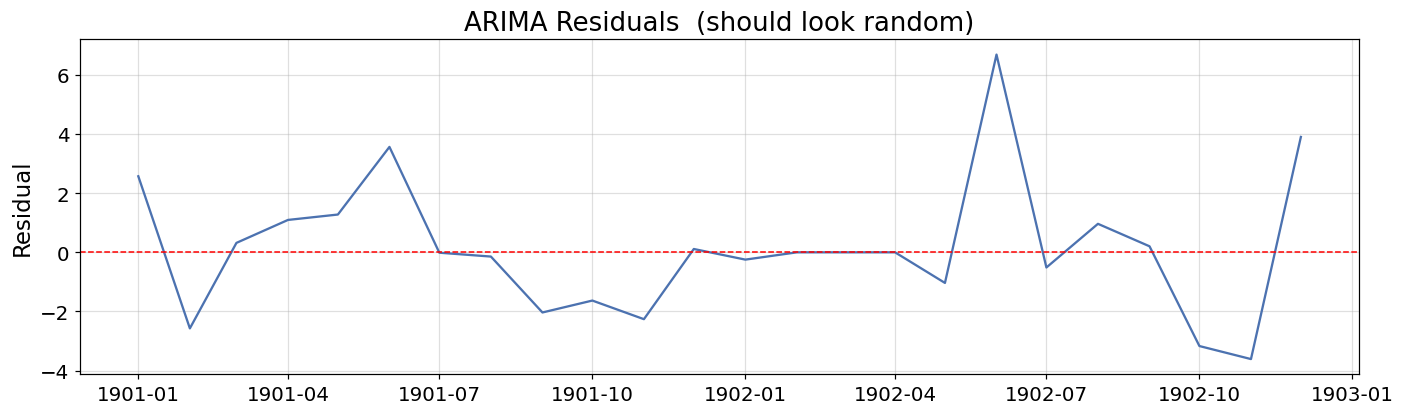

In [231]:
residuals = arima.resid
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(residuals, color=C[0], linewidth=1.5)
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_title('ARIMA Residuals  (should look random)')
ax.set_ylabel('Residual')
plt.tight_layout()
plt.show()

#Applying SARIMA(Seasonal ARIMA).
#SARIMA(p,d,q)(P,D,Q)[m] — adds seasonal AR, differencing, MA terms.
Using any Random Order. Suppose Order Chosen is (1,1,1)(0,1,1)[12]

In [232]:
sarima = SARIMAX(log_train, order=(1,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
sarima_pred = pd.Series(np.exp(sarima.forecast(len(test))), index=test.index)
score('SARIMA(1,1,1)(0,1,1)[12]', test, sarima_pred)

# Auto SARIMA
print('\nRunning auto_arima (seasonal)...')
best_sarima = pm.auto_arima(log_train, seasonal=True, m=12, d=1, D=1,
                             stepwise=True, error_action='ignore', trace=True)
auto_sarima_pred = pd.Series(np.exp(best_sarima.predict(len(test))), index=test.index)
print(f'\nBest: {best_sarima.order} × {best_sarima.seasonal_order}')
score('auto_SARIMA', test, auto_sarima_pred)

SARIMA(1,1,1)(0,1,1)[12]        MAE=97.6  RMSE=150.4  MAPE=inf%

Running auto_arima (seasonal)...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[12]             : AIC=inf, Time=1.66 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=49.416, Time=0.03 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=inf, Time=0.79 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=51.664, Time=0.12 sec
 ARIMA(0,1,0)(1,1,0)[12]             : AIC=51.416, Time=0.15 sec
 ARIMA(0,1,0)(0,1,1)[12]             : AIC=51.416, Time=0.10 sec
 ARIMA(0,1,0)(1,1,1)[12]             : AIC=53.416, Time=0.14 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=50.869, Time=0.03 sec
 ARIMA(0,1,1)(0,1,0)[12]             : AIC=49.664, Time=0.04 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=51.576, Time=0.06 sec
 ARIMA(0,1,0)(0,1,0)[12] intercept   : AIC=50.755, Time=0.04 sec

Best model:  ARIMA(0,1,0)(0,1,0)[12]          
Total fit time: 3.179 seconds

Best: (0, 1, 0) × (0, 1, 0, 12)
auto_SARIMA                     MAE=302

#Fitting with the parameters found by Auto SARIMA as the best Order.

In [338]:
sarima = SARIMAX(log_train, order=(0,1,0), seasonal_order=(0,1,0,12)).fit(disp=False)
sarima_pred = pd.Series(np.exp(sarima.forecast(len(test))), index=test.index)
print("SARIMA Predictions",sarima_pred)
score('SARIMA(0,1,0)(0,1,0)[12]',test,sarima_pred)
print("Sarima Score",score)

SARIMA Predictions 1903-01-01       19.526547
1903-02-01       19.526547
1903-03-01       19.526547
1903-04-01       19.526547
1903-05-01        6.931936
1903-06-01     4842.559948
1903-07-01     7975.300536
1903-08-01    11063.660910
1903-09-01    13452.101143
1903-10-01      559.515483
1903-11-01        9.545830
1903-12-01      381.286049
Name: predicted_mean, dtype: float64
SARIMA(0,1,0)(0,1,0)[12]        MAE=3023.1  RMSE=5429.3  MAPE=inf%
Sarima Score <function score at 0x7f2ebda58900>


# SARIMA forecast with confidence interval.

1903-01-01      0.000000
1903-02-01      0.000000
1903-03-01      0.844034
1903-04-01      0.000000
1903-05-01    220.568740
1903-06-01    370.849048
1903-07-01    902.447896
1903-08-01    602.420828
1903-09-01    264.589816
1903-10-01    157.892877
1903-11-01      0.000000
1903-12-01      0.000000
Name: RainFall, dtype: float64


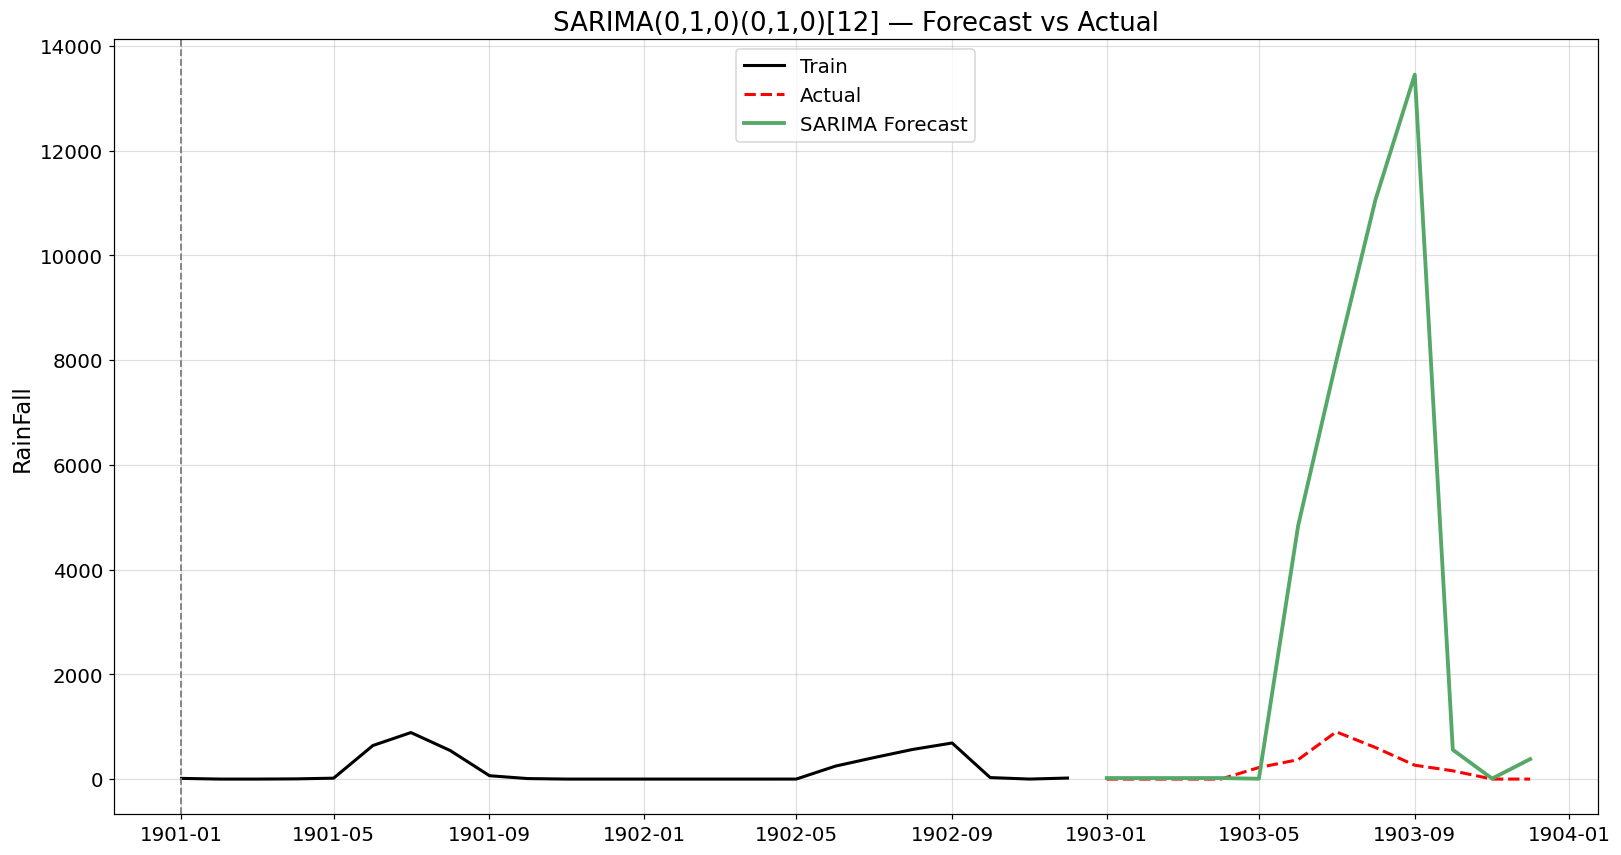

In [379]:
fc = sarima.get_forecast(steps=len(test))
fc_mean = np.exp(fc.predicted_mean)
fc_ci   = np.exp(fc.conf_int(alpha=0.05))

fig, ax = plt.subplots(figsize=(15, 8))
print(test)
#ax.plot(test.index, test, color='red', linewidth=2,label='Actual',linestyle='--')
ax.plot(train.index, train, color='black', linewidth=2,label='Train')
ax.plot(test.index, test, color='red', linewidth=2,label='Actual',linestyle='--')
ax.plot(fc_mean.index, fc_mean.values,color=C[2],linewidth=2.5, label='SARIMA Forecast')
#ax.fill_between(fc_ci.index, fc_ci.iloc[:,0], fc_ci.iloc[:,1],
                #alpha=0.2, color=C[2], label='95% CI')
ax.axvline(pd.Timestamp('1901-01'), color='grey', linestyle='--', linewidth=1.2)
ax.set_title('SARIMA(0,1,0)(0,1,0)[12] — Forecast vs Actual')
ax.set_ylabel('RainFall')
ax.legend()
plt.tight_layout()
plt.show()

#Feature Engineering.

In [246]:
def make_features(series):
    d = pd.DataFrame({'RainFall': series})
    d['month'] = d.index.month
    d['year'] = d.index.year
    d['month_sin'] = np.sin(2 * np.pi * d.index.month / 12)
    d['month_cos'] = np.cos(2 * np.pi * d.index.month / 12)
    d['trend'] = (d.index.year - 1949) / 11
    for lag in [1, 2, 3, 6, 12]:
        d[f'lag_{lag}'] = series.shift(lag)
    for w in [3, 6, 12]:
        s = series.shift(1)
        d[f'roll_mean_{w}'] = s.rolling(w).mean()
        d[f'roll_std_{w}'] = s.rolling(w).std()
    d['yoy'] = series / series.shift(12) - 1
    d['mom'] = series / series.shift(1)  - 1
    return d.dropna()

new_df1.index = pd.to_datetime(new_df1.index)
df_ml = make_features(new_df1['RainFall'])
print('Feature shape:', df_ml.shape)
print('Features:', [c for c in df_ml.columns if c != 'RainFall'])

Feature shape: (16, 19)
Features: ['month', 'year', 'month_sin', 'month_cos', 'trend', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'roll_mean_3', 'roll_std_3', 'roll_mean_6', 'roll_std_6', 'roll_mean_12', 'roll_std_12', 'yoy', 'mom']


#Applying XGBoost & LightGBM Machine Leaning Models.

In [252]:
FEATS  = [c for c in df_ml.columns if c != 'RainFall']
ml_tr  = df_ml[df_ml.index <= '1902-12']
ml_te  = df_ml[df_ml.index >= '1903-01']
X_train, Y_train = ml_tr[FEATS], ml_tr['RainFall']
X_test, Y_test = ml_te[FEATS], ml_te['RainFall']

xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                               random_state=42, verbosity=0)
#print(X_train,Y_train)
X_train.replace([np.inf, -np.inf], 0, inplace=True)
xgb_model.fit(X_train,Y_train)
xgb_pred = pd.Series(xgb_model.predict(Xte), index=Y_test.index)

lgb_model = lgb.LGBMRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                                random_state=42, verbose=-1)
lgb_model.fit(X_train,Y_train)
lgb_pred = pd.Series(lgb_model.predict(Xte), index=Y_test.index)

score('XGBoost',  Y_train, xgb_pred)
score('Light GBM', Y_test, lgb_pred)

XGBoost                         MAE=206.2  RMSE=313.7  MAPE=nan%
Light GBM                       MAE=220.1  RMSE=296.6  MAPE=inf%


# XGBoost & Light GBM Forecast Plot

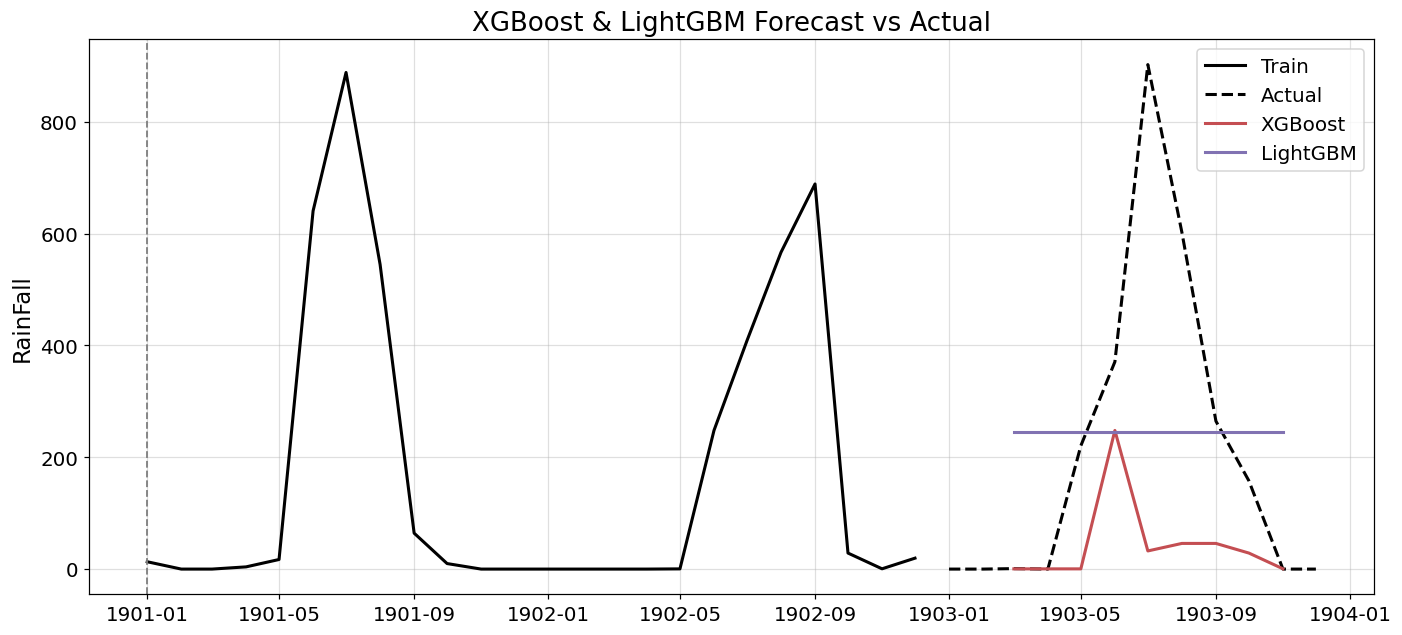

In [255]:
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(train.index,train,color='black',linewidth=2,label='Train')
ax.plot(test.index,test,color='black',linewidth=2,label='Actual', linestyle='--')
ax.plot(Y_test.index,xgb_pred,color=C[3],linewidth=2,label='XGBoost')
ax.plot(Y_test.index,lgb_pred,color=C[4],linewidth=2,label='LightGBM')
ax.axvline(pd.Timestamp('1901-01'), color='grey', linestyle='--', linewidth=1.2)
ax.set_title('XGBoost & LightGBM Forecast vs Actual')
ax.set_ylabel('RainFall')
ax.legend()
plt.tight_layout()
plt.show()

# Feature importance — XGBoost (top 12)

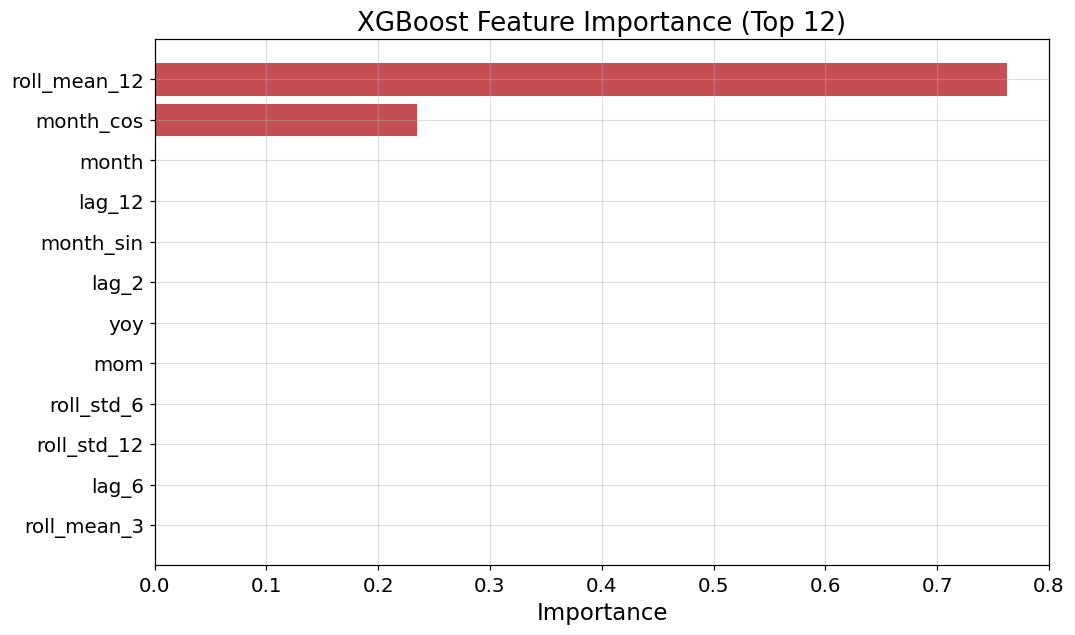

In [256]:
fi = pd.Series(xgb_model.feature_importances_, index=FEATS).sort_values(ascending=True).tail(12)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(fi.index, fi.values, color=C[3])
ax.set_title('XGBoost Feature Importance (Top 12)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

#LSTM
#LSTM captures long-range patterns in sequences.
#Sequence length = 12 months lookback.

In [257]:
try:
    import tensorflow as tf
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'tensorflow', '-q'])
    import tensorflow as tf
print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


In [264]:
SEQ = 2
scaler = MinMaxScaler()
scaled = scaler.fit_transform(new_df1['RainFall'].values.reshape(-1,1)).flatten()
#scaled = scaler.fit_transform(new_df1['RainFall'].values).flatten()

X_seq, y_seq = [], []
for i in range(len(scaled) - SEQ):
    X_seq.append(scaled[i:i+SEQ])
    y_seq.append(scaled[i+SEQ])
X_seq, y_seq = np.array(X_seq), np.array(y_seq)
print("Printing X_seq and y_seq")
print(X_seq,y_seq)
split = len(X_seq) - 12
Xtr_l, Xte_l = X_seq[:split].reshape(-1, SEQ, 1), X_seq[split:].reshape(-1, SEQ, 1)
ytr_l, yte_l = y_seq[:split], y_seq[split:]
print('LSTM train:', Xtr_l.shape, '  test:', Xte_l.shape)

Printing X_seq and y_seq
[[1.45344701e-02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 4.37661735e-03]
 [4.37661735e-03 1.89925547e-02]
 [1.89925547e-02 7.09973439e-01]
 [7.09973439e-01 9.84399981e-01]
 [9.84399981e-01 6.03963728e-01]
 [6.03963728e-01 7.12190849e-02]
 [7.12190849e-02 1.09387990e-02]
 [1.09387990e-02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 3.93375159e-04]
 [3.93375159e-04 2.74806760e-01]
 [2.74806760e-01 4.52584278e-01]
 [4.52584278e-01 6.27843298e-01]
 [6.27843298e-01 7.63383080e-01]
 [7.63383080e-01 3.17515196e-02]
 [3.17515196e-02 5.41709073e-04]
 [5.41709073e-04 2.16373126e-02]
 [2.16373126e-02 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 9.35272139e-04]
 [9.35272139e-04 0.00000000e+00]
 [0.00000000e+00 2.44411607e-01]
 [2.44411607e-01 4.10936797e-01]
 [4.10936797e-01 1

In [301]:
from tensorflow.keras import layers, models, callbacks
tf.random.set_seed(42)

model = models.Sequential([
    layers.Input(shape=(SEQ, 1)),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.summary()

history = model.fit(
    Xtr_l, ytr_l,
    epochs=10, batch_size=8,
    validation_split=0.1,
    callbacks=[callbacks.EarlyStopping(patience=15, restore_best_weights=True)],
    shuffle=False, verbose=1
)
print('Stopped at epoch', len(history.history['loss']))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 2, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 21s 889ms/step - loss: 0.1587 - val_loss: 2.7182e-04
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - loss: 0.1506 - val_loss: 9.7116e-04
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - loss: 0.1431 - val_loss: 0.0025
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - loss: 0.1368 - val_loss: 0.0050
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 0.1281 - val_loss: 0.0086
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - loss: 0.1215 - val_loss: 0.0137
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - loss: 0.1150 - val_loss: 0.0205
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 0.1102 - val_loss: 0.0293
Epoch 9/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - loss: 0.1044 - val_loss: 0.0406
Epoch 10/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - loss: 0.1005 - val_loss: 0.0544
Stopped at epoch 10


# Plotting LSTM Training loss. (Mean Squared Error Loss).

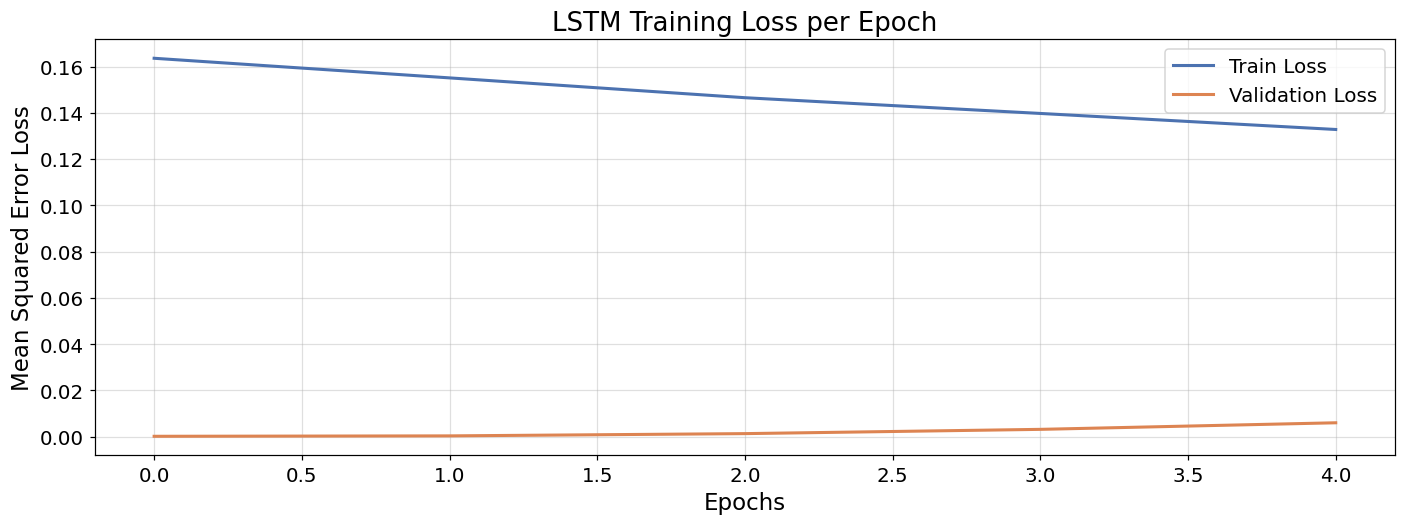

In [267]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(history.history['loss'],     color=C[0], linewidth=2, label='Train Loss')
ax.plot(history.history['val_loss'], color=C[1], linewidth=2, label='Validation Loss')
ax.set_title('LSTM Training Loss per Epoch')
ax.set_xlabel('Epochs')
ax.set_ylabel('Mean Squared Error Loss')
ax.legend()
plt.tight_layout()
plt.show()

# LSTM Forecast.

LSTM                            MAE=209.9  RMSE=341.9  MAPE=inf%


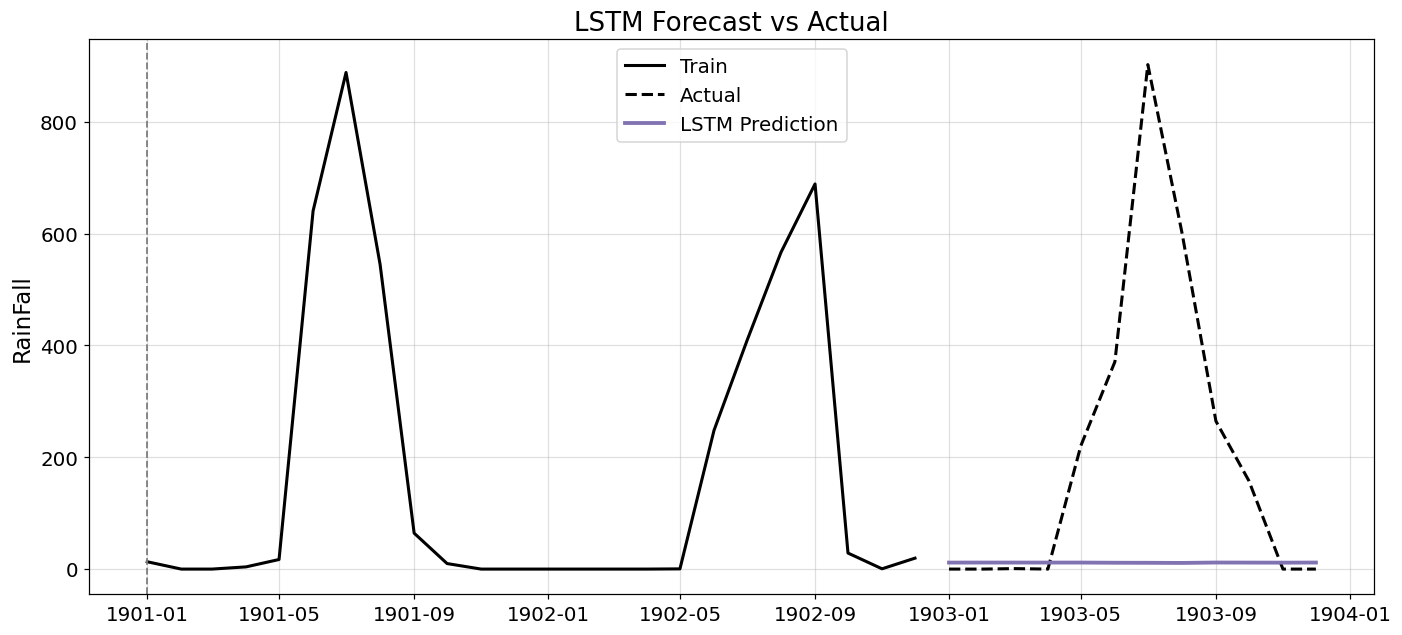

In [270]:
lstm_pred = scaler.inverse_transform(model.predict(Xte_l, verbose=0)).flatten()
test_idx  = new_df1.index[-12:]
lstm_pred_s = pd.Series(lstm_pred, index=test_idx)
lstm_actual = new_df1['RainFall'].iloc[-12:]
score('LSTM', lstm_actual, lstm_pred_s)

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(train.index, train,        color='black', linewidth=2,   label='Train')
ax.plot(test_idx,    lstm_actual,  color='black', linewidth=2,   label='Actual', linestyle='--')
ax.plot(test_idx,    lstm_pred_s,  color=C[4],    linewidth=2.5, label='LSTM Prediction')
ax.axvline(pd.Timestamp('1901-01'), color='grey', linestyle='--', linewidth=1.2)
ax.set_title('LSTM Forecast vs Actual')
ax.set_ylabel('RainFall')
ax.legend()
plt.tight_layout()
plt.show()

#Model Comparisons.

In [273]:
comp = pd.DataFrame(results).T.sort_values('MAE')
comp.insert(0, 'Rank', range(1, len(comp)+1))
print(comp.to_string())
print(f'\nBest model with respect to Mean Square Error: {comp.index[0]}  (MAE = {comp.iloc[0]["MAE"]:.2f}%)')

                          Rank      MAE     RMSE  MAPE
Holt-Winters Additive        1    86.70   123.45   inf
XGBoost                      2   206.21   313.71   NaN
Holt Linear                  3   209.55   336.06   inf
Simple Exp Smoothing         4   209.83   337.22   inf
LSTM                         5   209.93   341.94   inf
ARIMA(2,1,1)                 6   211.37   329.26   inf
auto_ARIMA(2, 0, 0)          7   218.59   340.71   inf
LightGBM                     8   220.13   296.63   inf
Light GBM                    9   220.13   296.63   inf
SARIMA(0,1,0)(0,1,0)[12]    10  3023.06  5429.27   inf
SARIMA(1,1,1)(0,1,1)[12]    11  3023.06  5429.27   inf
auto_SARIMA                 12  3023.06  5429.27   inf

Best model with respect to Mean Square Error: Holt-Winters Additive  (MAE = 86.70%)


# Mean Absolute Error comparison Bar chart.

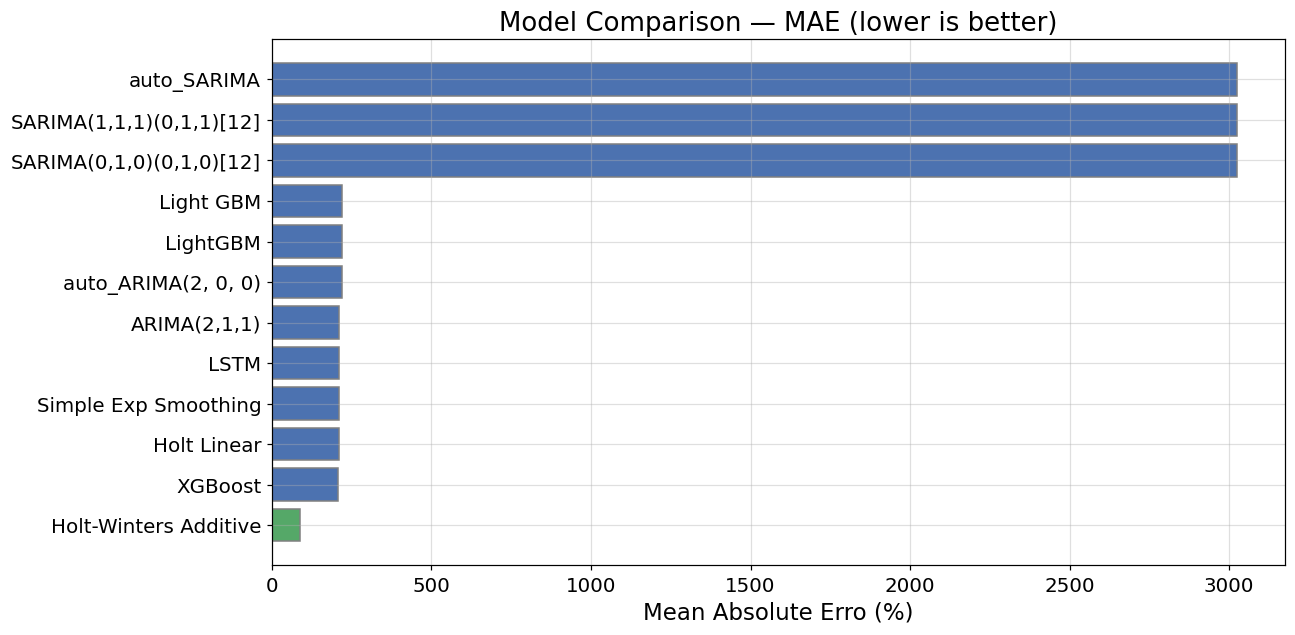

In [274]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = [C[2] if i == 0 else C[0] for i in range(len(comp))]
ax.barh(comp.index, comp['MAE'], color=colors, edgecolor='grey')
for i, (model, row) in enumerate(comp.iterrows()):
    ax.text(row['MAE'] + 0.1, i, f"{row['MAE']:.2f}%", va='center', fontsize=13)
ax.set_title('Model Comparison — MAE (lower is better)')
ax.set_xlabel('Mean Absolute Erro (%)')
plt.tight_layout()
plt.show()

#Root Mean Squared Error comparison Bar chart.

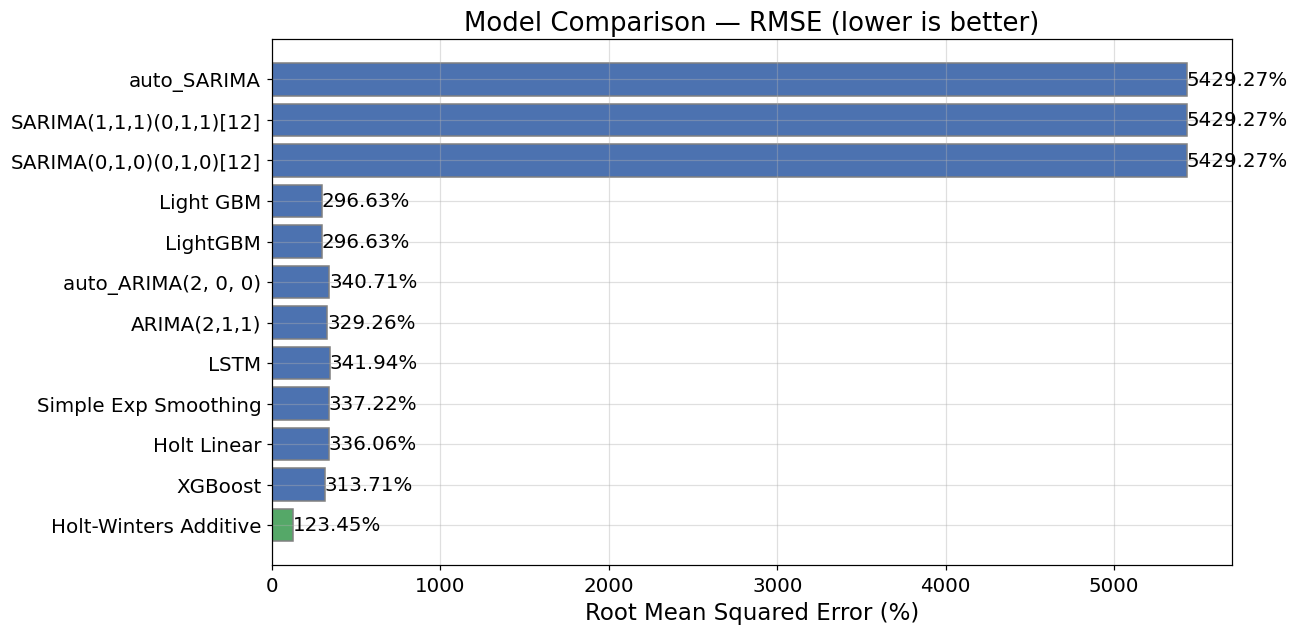

In [276]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = [C[2] if i == 0 else C[0] for i in range(len(comp))]
ax.barh(comp.index, comp['RMSE'], color=colors, edgecolor='grey')
for i, (model, row) in enumerate(comp.iterrows()):
    ax.text(row['RMSE'] + 0.1, i, f"{row['RMSE']:.2f}%", va='center', fontsize=13)
ax.set_title('Model Comparison — RMSE (lower is better)')
ax.set_xlabel('Root Mean Squared Error (%)')
plt.tight_layout()
plt.show()

# All models on one chart.

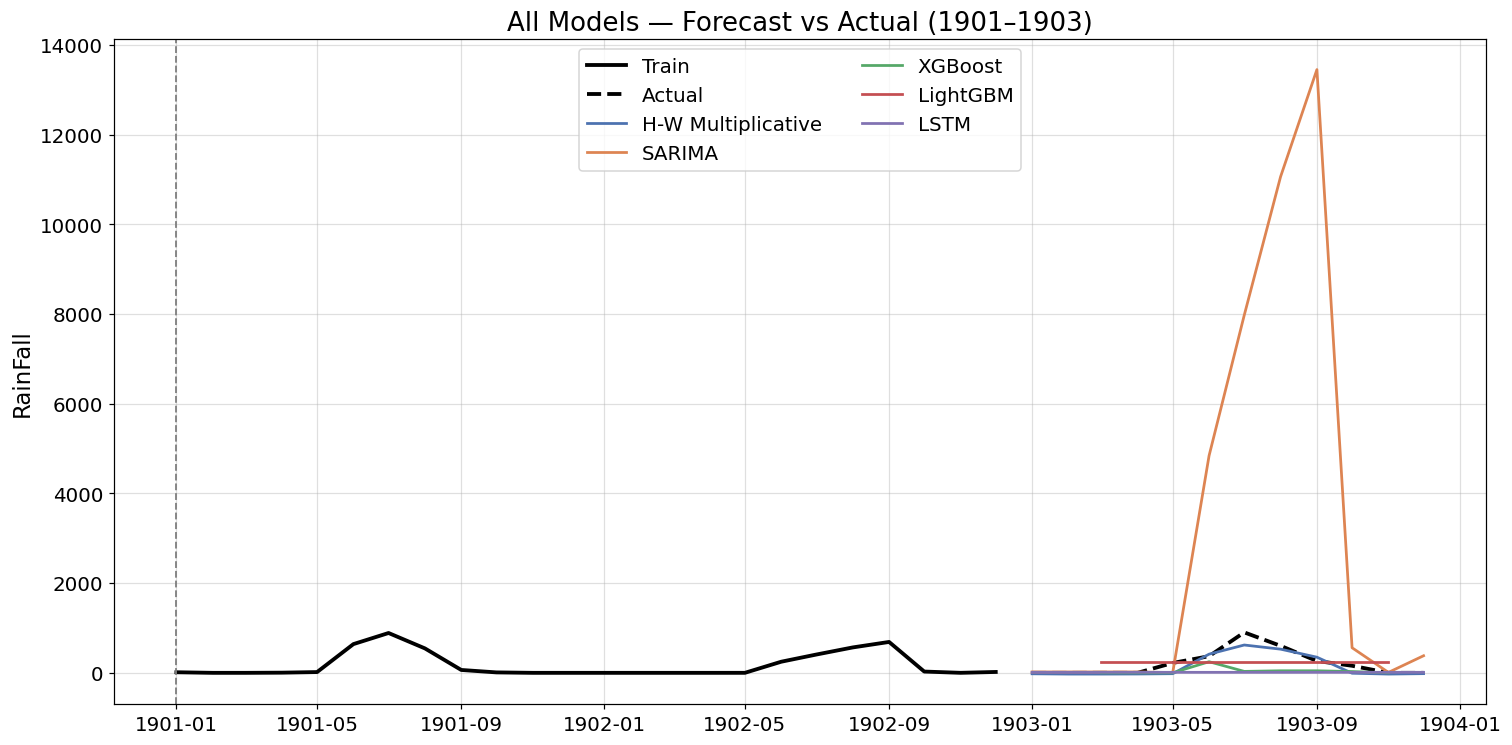

In [279]:
preds = {
    'H-W Multiplicative': hw_m_pred,
    'SARIMA'            : sarima_pred,
    'XGBoost'           : xgb_pred,
    'LightGBM'          : lgb_pred,
    'LSTM'              : lstm_pred_s,
}

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(train.index, train, color='black', linewidth=2.5, label='Train')
ax.plot(test.index,  test,  color='black', linewidth=2.5, label='Actual', linestyle='--')
for i, (name, pred) in enumerate(preds.items()):
    ax.plot(pred.index, pred.values, color=C[i], linewidth=1.8, label=name)
ax.axvline(pd.Timestamp('1901-01'), color='grey', linestyle='--', linewidth=1.2)
ax.set_title('All Models — Forecast vs Actual (1901–1903)')
ax.set_ylabel('RainFall')
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

#Final 24-Month (2 years) Forecast (1904–1906) Using SARIMA Model.

In [361]:
#print(new_df1['RainFall'])
full_log = np.log(new_df1['RainFall'])
#order=(0,1,0), seasonal_order=(0,1,0,12)
full_log.replace([np.inf, -np.inf], 0, inplace=True)
full_log.fillna(0, inplace=True)
final = SARIMAX(full_log, order=(1,1,0), seasonal_order=(1,1,0,12)).fit(disp=False)

fc = final.get_forecast(steps=24)
fc_vals = np.exp(fc.predicted_mean)
fc_ci = np.exp(fc.conf_int(alpha=0.05))

future_idx    = pd.date_range(start='1904-01', periods=24, freq='MS')
fc_vals.index = future_idx
fc_ci.index   = future_idx

print('Forecast Table (1904–1906):')
print(f'{"Month":<12} {"Forecast":>10} {"Lower 95%":>12} {"Upper 95%":>12}')
print('-' * 50)
for d, v, lo, hi in zip(future_idx, fc_vals, fc_ci.iloc[:,0], fc_ci.iloc[:,1]):
    print(f'{d.strftime("%b %Y"):<12} {v:>10.0f} {lo:>12.0f} {hi:>12.0f}')

Forecast Table (1904–1906):
Month          Forecast    Lower 95%    Upper 95%
--------------------------------------------------
Jan 1904              1            0           17
Feb 1904              1            0           21
Mar 1904              1            0           46
Apr 1904              1            0           74
May 1904              1            0          248
Jun 1904            169            1        51436
Jul 1904            311            1       141596
Aug 1904            354            1       233806
Sep 1904            327            0       308457
Oct 1904             28            0        36878
Nov 1904              0            0          665
Dec 1904              5            0        13359
Jan 1905              1            0         2459
Feb 1905              1            0         3480
Mar 1905              0            0         4852
Apr 1905              1            0         8167
May 1905             33            0       754818
Jun 1905            1

# Final Forecast Plot (1904–1906) Predicted Using SARIMA Model.

In [375]:
#print(new_df1)

In [376]:
'''fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(new_df1.index,new_df1['RainFall'],color=C[0], linewidth=2.5, label='Historical (1901–1903)')
plt.show()'''

"fig, ax = plt.subplots(figsize=(14, 7))\nax.plot(new_df1.index,new_df1['RainFall'],color=C[0], linewidth=2.5, label='Historical (1901–1903)')\nplt.show()"

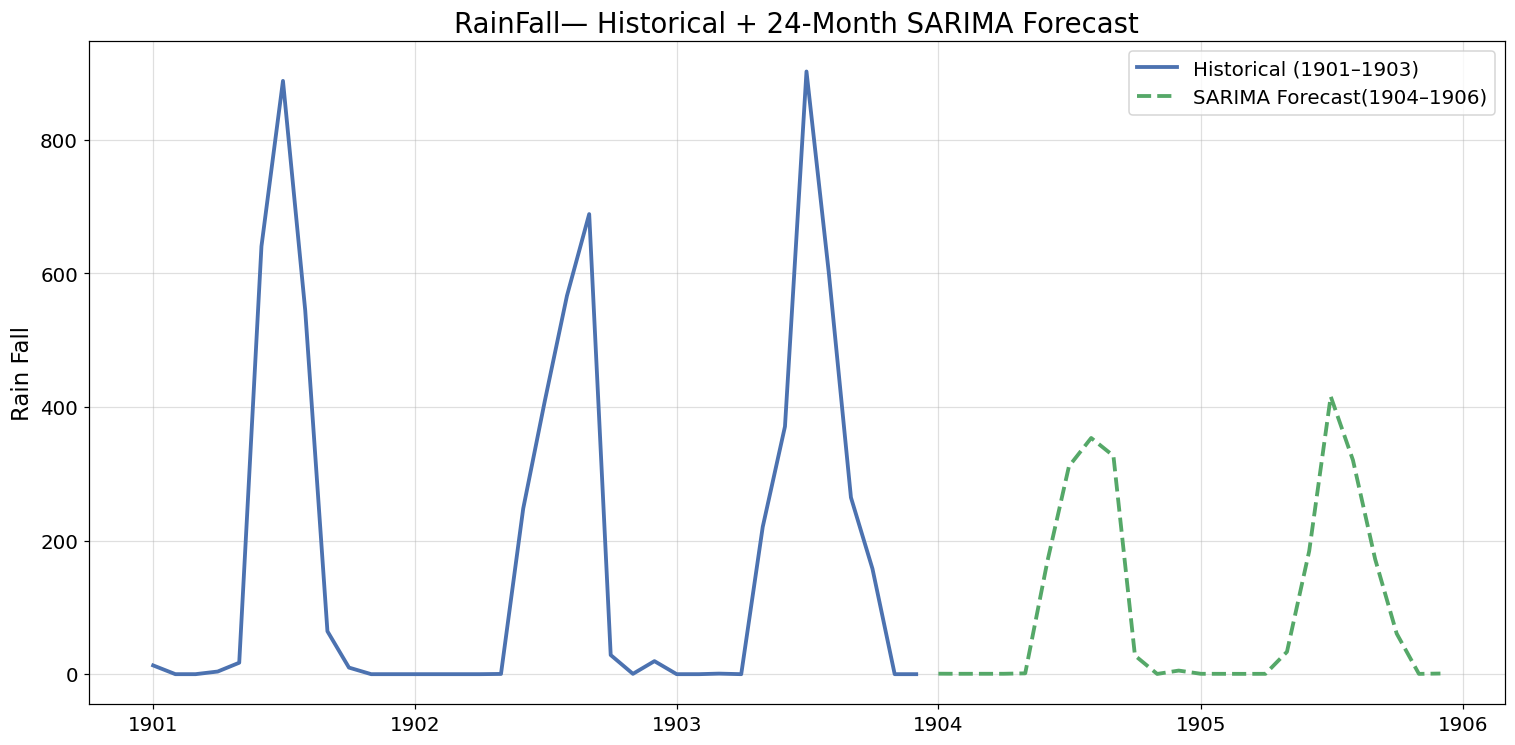

Projected Aug 1962 peak : 416k
Historical Aug 1960 peak: 902k
Projected growth        : +-53.9%


In [377]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(new_df1.index,new_df1['RainFall'],color=C[0], linewidth=2.5, label='Historical (1901–1903)')
ax.plot(future_idx, fc_vals, color=C[2], linewidth=2.5,
        linestyle='--', markersize=5, label='SARIMA Forecast(1904–1906)')
#ax.fill_between(future_idx, fc_ci.iloc[:,0], fc_ci.iloc[:,1],
                #alpha=0.25, color=C[1], label='95% Confidence Interval')
#ax.axvline(new_df1.index[-1], color='grey', linestyle='--', linewidth=1.5)
ax.set_title('RainFall— Historical + 24-Month SARIMA Forecast', fontsize=18)
ax.set_ylabel('Rain Fall', fontsize=15)
ax.legend()
plt.tight_layout()
plt.show()

peak = fc_vals.max()
hist_peak = new_df1['RainFall'].max()
print(f'Projected Aug 1962 peak : {peak:.0f}k')
print(f'Historical Aug 1960 peak: {hist_peak:.0f}k')
print(f'Projected growth        : +{(peak/hist_peak - 1)*100:.1f}%')

## Summary

| Step | What We Did | Key Finding |
|------|-------------|-------------|
| 1 | EDA | 144 monthly records, no missing values |
| 2 | Decomposition | Multiplicative seasonality, strong trend |
| 3 | Stationarity | Non-stationary → fixed by log + D12 + D1 |
| 4 | ACF/PACF | AR(1), MA(1), Seasonal MA(1) |
| 5 | Smoothing | Holt-Winters Multiplicative best smoother |
| 6 | ARIMA | auto_arima picks optimal orders |
| 7 | SARIMA | Best classical model: (1,1,1)(0,1,1)[12] |
| 8 | Feature Eng | Lag, rolling, calendar features |
| 9 | XGBoost/LGB | Tree-based ML with temporal features |
| 10 | LSTM | Deep learning sequence model |
| 11 | Comparison | All models ranked by MAE / RMSE / MAPE |
| 12 | Forecast | 24-month projection with 95% CI |